# **Preparação de dados para análise da Pesquisa Nacional de Saúde de 2019**

Neste notebook, realizamos o pré-processamento dos dados da Pesquisa Nacional de Saúde (PNS) de 2019, etapa crucial para a construção de um modelo preditivo capaz de identificar os fatores que influenciam o uso dos serviços de saúde pela população brasileira. Através de técnicas de limpeza e transformação de dados, eliminamos inconsistências, padronizamos os formatos e criamos novas variáveis relevantes para a análise. Essa preparação minuciosa garantiu a qualidade e a consistência da base de dados, permitindo a identificação de padrões e tendências que serão utilizados para treinar e avaliar o modelo preditivo. Ao final deste processo, obtivemos um conjunto de dados estruturado e pronto para ser utilizado nas próximas etapas da pesquisa, contribuindo para a obtenção de resultados mais precisos e confiáveis.

## **Etapa 1 - Importação de Bibliotecas**

Nesta etapa do notebook, realizamos a instalação e carregamento de diversos pacotes do R, que são ferramentas essenciais para a manipulação, análise e visualização dos dados da Pesquisa Nacional de Saúde (PNS) 2019. Cada pacote oferece funcionalidades específicas que serão utilizadas nas próximas etapas do projeto.

**Pacotes e suas Funcionalidades:**

  * **PNSIBGE:** Pacote específico para trabalhar com dados da PNS, facilitando a leitura e o acesso às informações coletadas pela pesquisa.
  
  * **survey:** Utilizado para análise de dados complexos, como os provenientes de pesquisas amostrais, permitindo calcular estimativas e seus erros padrão de forma correta.
  
  * **openxlsx:** Permite a leitura e escrita de arquivos Excel de forma eficiente, facilitando a importação e exportação de dados.
  
  * **dplyr:** Pacote do tidyverse, oferece um conjunto de funções para manipulação de dados de forma rápida e intuitiva, como seleção, filtragem, ordenação e agregação.
  
  * **ggplot2:** Também do tidyverse, é a principal biblioteca para criação de gráficos de alta qualidade, permitindo visualizar os dados de diversas formas.
  
  * **corrplot:** Cria visualizações de matrizes de correlação, ajudando a identificar as relações entre as variáveis.
  
  * **reshape2:** Permite transformar dados entre diferentes formatos, como de longo para largo e vice-versa.
  
  * **igraph:** Utilizado para análise de redes, permitindo modelar e visualizar relações entre os dados.
  
  * **ggraph:** Extensão do ggplot2 para criação de gráficos de redes, combinando a flexibilidade do ggplot2 com as funcionalidades do igraph.
  
  * **ggrepel:** Permite adicionar rótulos a gráficos evitando sobreposições, melhorando a legibilidade das visualizações.

In [1]:
# Instalando pacotes necessários
install.packages("PNSIBGE")   # Pacote para trabalhar com dados da PNS
install.packages("survey")    # Pacote para análise de dados complexos (pesquisas amostrais)
install.packages("openxlsx")  # Pacote para ler e escrever arquivos Excel
install.packages("dplyr")     # Pacote para manipulação de dados (tidyverse)
install.packages("ggplot2")   # Pacote para criação de gráficos (tidyverse)
install.packages("corrplot")  # Pacote para visualização de matrizes de correlação
install.packages("reshape2")  # Pacote para transformar dados entre diferentes formatos
install.packages("igraph")    # Pacote para análise de redes
install.packages("ggraph")    # Pacote para gráficos de redes (extensão do ggplot2)
install.packages("ggrepel")   # Pacote para adicionar rótulos a gráficos evitando sobreposições

library(PNSIBGE)
library(survey)
library(openxlsx)
library(dplyr)
library(ggplot2)
library(corrplot)
library(reshape2)
library(igraph)
library(ggraph)
library(ggrepel)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘bitops’, ‘minqa’, ‘numDeriv’, ‘mitools’, ‘RcppArmadillo’, ‘projmgr’, ‘RCurl’, ‘survey’, ‘timeDate’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘plyr’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘tweenr’, ‘polyclip’, ‘RcppEigen’, ‘gridExtra

## **Etapa 2 - Importação e Filtragem de Dados**

### **2.1 - Importação do Plano Amostral - PNS 2019**

Nessa etapa, é realizada a importação dos dados da Pesquisa Nacional de Saúde de 2019.

In [2]:
# Carrega os dados da PNS de 2019 em um dataframe
planoAmostralTotal <- get_pns(year=2019, design=FALSE)

# Exibir as primeiras linhas do dataframe, permitindo verificar se os dados foram carregados corretamente
head(planoAmostralTotal)

V0020,V0001,V0024,UPA_PNS,V0006_PNS,V0015,V0022,V0026,V0031,V0025A,⋯,VDF002,VDF003,VDF004,VDL001,VDM001,VDP001,VDR001,VDDATA,ID_DOMICILIO,Deflator
<chr>,<fct>,<chr>,<chr>,<chr>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<dbl>,<dbl>,<fct>,<dbl>,<fct>,<fct>,<fct>,<chr>,<chr>,<dbl>
2019,Rondônia,1110011,110000016,0001,Realizada,6,Urbano,Capital,Selecionado,⋯,2098,350,Mais de ¼ até ½ salário mínimo,NA,NA,NA,NA,20220504,1100000160001,1
2019,Rondônia,1110011,110000016,0001,Realizada,6,Urbano,Capital,Não selecionado,⋯,2098,350,Mais de ¼ até ½ salário mínimo,NA,NA,NA,NA,20220504,1100000160001,1
2019,Rondônia,1110011,110000016,0001,Realizada,6,Urbano,Capital,Não selecionado,⋯,2098,350,Mais de ¼ até ½ salário mínimo,NA,NA,NA,NA,20220504,1100000160001,1
2019,Rondônia,1110011,110000016,0001,Realizada,6,Urbano,Capital,Não aplicável,⋯,2098,350,Mais de ¼ até ½ salário mínimo,NA,NA,NA,NA,20220504,1100000160001,1
2019,Rondônia,1110011,110000016,0001,Realizada,6,Urbano,Capital,Não aplicável,⋯,2098,350,Mais de ¼ até ½ salário mínimo,NA,NA,NA,NA,20220504,1100000160001,1
2019,Rondônia,1110011,110000016,0001,Realizada,6,Urbano,Capital,Não aplicável,⋯,2098,350,Mais de ¼ até ½ salário mínimo,NA,NA,NA,NA,20220504,1100000160001,1


### **2.2 - Filtragem do Plano Amostral - PNS 2019**

Nesta etapa do processo, realizamos a seleção e filtragem das colunas relevantes para a análise, criando um novo conjunto de dados mais conciso e focado nas variáveis de interesse para a pesquisa. Além disso, renomeamos as colunas com nomes mais descritivos, facilitando a interpretação dos dados.

#### **2.2.3 - Atributos**


1. **UPA_PNS: Peso (V0091)**
        Indicar o peso do morador selecionado.

2. **V0001: UF**
        Estado em que a pessoa vive.

3. **V0024: Extrato**
        Extrato.

4. **V0026: Zona**
        1: Rural
        2: Urbana

5. **V0006_PNS: Ordem do Domicílio**
        Número da ordem do domicílio na PNS.

6. **VDD004A: Grau de Ensino**
        Grau de escolaridade da pessoa:
          1: Sem instrução
          2: Fundamental incompleto ou equivalente
          3: Fundamental completo ou equivalente
          4: Médio incompleto ou equivalente
          5: Médio completo ou equivalente
          6: Superior incompleto ou equivalente
          7: Superior completo

7. **VDF004: Renda**
        Renda mensal da pessoa:
          1: Até ¼ salário mínimo
          2: Mais de ¼ até ½ salário mínimo
          3: Mais de ½ até 1 salário mínimo
          4: Mais de 1 até 2 salários mínimos (R$ 998,01 até R$ 1996,00)
          5: Mais de 2 até 3 salários mínimos
          6: Mais de 3 até 5 salários mínimos
          7: Mais de 5 salários mínimos

8. **B001: Cadastro UBS**
        Se o domicílio da pessoa está cadastrado na unidade de saúde da família:
          1: Sim
          2: Não
          3: Não sabe

9. **B003: Agente Comunitário**
        Se a pessoa recebe visita de algum Agente Comunitário:
          1: Mensalmente
          2: A cada 2 meses
          3: De 2 a 4 vezes
          4: Uma vez
          5: Nunca recebeu

10. **C00301: Número de Ordem**
        Número da Ordem

11. **C006: Sexo**
         Sexo da pessoa:
           1: Homem
           2: Mulher

12. **C008: Idade**
         Idade em anos da pessoa.

13. **C009: Raça**
         Cor ou raça em que a pessoa se identifica:
           1: Branca
           2: Preta
           3: Amarela
           4: Parda
           5: Indígena

14. **C011: Estado Civil**
         O estado civil da pessoa:
           1: Casado(a)
           2: Divorciado(a) ou desquitado(a) ou separado(a) judicialmente
           3: Viúvo(a)
           4: Solteiro(a)

15. **D001: Ler e Escrever**
         Se a pessoa sabe ler e escrever:
           1: Sim
           2: Não
           3: Ignorado

16. **D00201: Escola**
         Se a pessoa estuda, o que a inclui desde a pré-escola até o doutorado:
           1: Sim
           2: Não
           3: Ignorado

17. **E001: Trabalha**
         Se a pessoa trabalha:
           1: Sim
           2: Não
           3: Ignorado

18. **I00102: Plano de Saúde**
         Se a pessoa possui plano de saúde particular:
           1: Sim
           2: Não
           3: Ignorado

19. **J001: Estado de Saúde**
         Como a pessoa considera o estado de saúde dela:
           1: Muito bom
           2: Bom
           3: Regular
           4: Ruim
           5: Muito ruim

20. **J014: Serviço de Saúde**
         Se a pessoa procurou algum atendimento relacionado à própria saúde nas duas últimas semanas:
           1: Sim
           2: Não
           3: Ignorado

21. **J037: Internação**
         Se a pessoa ficou internada nos últimos 12 meses:
           1: Sim
           2: Não
           3: Ignorado

22. **P027: Álcool**
         Com que frequência a pessoa costuma consumir alguma bebida alcoólica:
           1: Não bebo nunca
           2: Menos de uma vez por mês
           3: Uma vez ou mais por mês

23. **P034: Exercício Físico**
         Se a pessoa pratica exercícios físicos:
           1: Sim
           2: Não
           3: Ignorado

24. **P050: Tabaco**
         Se a pessoa usa tabaco:
           1: Sim, diariamente
           2: Sim, menos que diariamente
           3: Não fumo atualmente

25. **P00104: Peso**
         Peso em quilos da pessoa.

26. **P00404: Altura**
         Altura em metros da pessoa

27. **Q060: Colesterol Alto**
         Se a pessoa recebeu diagnóstico de colesterol alto:
           1: Sim
           2: Não
           3: Ignorado

28. **Q068: AVC ou Derrame**
         Se a pessoa recebeu diagnóstico de AVC (Acidente Vascular Cerebral) ou derrame:
           1: Sim
           2: Não
           3: Ignorado

29. **Q073: AVC ou Derrame Limita Atividades**
         Em que grau o AVC ou derrame limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

30. **Q074: Asma**
         Se a pessoa recebeu diagnóstico de asma (ou bronquite asmática):
           1: Sim
           2: Não
           3: Ignorado

31. **Q078: Asma Limita Atividades**
         Em que grau a asma limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

32. **Q079: Artrite ou Reumatismo**
         Se a pessoa recebeu diagnóstico de artrite ou reumatismo:
           1: Sim
           2: Não
           3: Ignorado

33. **Q083: Artrite ou Reumatismo Limita Atividades**
         Em que grau a artrite ou reumatismo limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

34. **Q084: Dor na Coluna**
         Se a pessoa possui algum problema crônico de coluna, como dor crônica nas costas ou no pescoço, lombalgia, dor ciática, problemas nas vértebras ou disco:
           1: Sim
           2: Não
           3: Ignorado

35. **Q087: Dor na Coluna Limita Atividades**
         Em que grau o problema de coluna limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

36. **Q088: DORT**
         Se a pessoa recebeu diagnóstico de DORT (distúrbio osteomuscular relacionado ao trabalho):
           1: Sim
           2: Não
           3: Ignorado

37. **Q091: DORT Limita Atividades**
         Em que grau o DORT limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

38. **Q092: Depressão**
         Se a pessoa recebeu diagnóstico de depressão:
           1: Sim
           2: Não
           3: Ignorado

39. **Q109: Depressão Limita Atividades**
         Em que grau a depressão limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

40. **Q00201: Hipertensão**
         Se a pessoa recebeu diagnóstico de hipertensão arterial:
           1: Sim
           2: Não
           3: Ignorado

41. **Q028: Hipertensão Limita Atividades**
         Em que grau a hipertensão limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

42. **Q00202: Hipertensão na Gestação**
         Se a pessoa teve hipertensão arterial (pressão alta) durante algum período de gestação:
           1: Sim
           2: Não
           3: Ignorado

43. **Q03001: Diabetes**
         Se a pessoa recebeu diagnóstico de diabetes:
           1: Sim
           2: Não
           3: Ignorado

44. **Q03002: Diabetes na Gestação**
         Se a pessoa teve diabetes durante algum período da gestação:
           1: Sim
           2: Não
           3: Ignorado

45. **Q058: Diabetes Limita Atividades**
         Em que grau a diabetes limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

46. **Q06306: Cardiopatia**
         Se a pessoa recebeu diagnóstico de cardiopatia, tal como infarto, angina, insuficiência cardíaca ou outra:
           1: Sim
           2: Não
           3: Ignorado

47. **Q067: Cardiopatia Limita Atividades**
         Em que grau a cardiopatia limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

48. **Q120: Câncer**
         Se a pessoa recebeu diagnóstico de câncer:
           1: Sim
           2: Não
           3: Ignorado

49. **Q12301: Câncer Limita Atividades**
         Em que grau o câncer limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

50. **Q124: Insuficiência Renal Crônica**
         Se a pessoa recebeu diagnóstico de insuficiência renal crônica:
           1: Sim
           2: Não
           3: Ignorado

51. **Q127: Insuficiência Renal Limita Atividades**
         Em que grau a insuficiência renal limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

52. **Q11006: Doença Mental**
         Se a pessoa recebeu diagnóstico de doença mental:
           1: Sim
           2: Não
           3: Ignorado

53. **Q115: Doença Mental Limita Atividades**
         Em que grau a doença mental limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente

54. **Q11604: Doença Crônica no Pulmão**
         Se a pessoa recebeu diagnóstico de doença crônica no pulmão, tais como enfisema pulmonar, bronquite crônica ou DPOC (Doença Pulmonar Obstrutiva Crônica):
           1: Sim
           2: Não
           3: Ignorado

55. **Q119: Doença Crônica no Pulmão Limita Atividades**
         Em que grau a doença crônica no pulmão limita as atividades habituais da pessoa (tais como trabalhar, realizar afazeres domésticos etc):
           1: Não limita
           2: Um pouco
           3: Moderadamente
           4: Intensamente
           5: Muito intensamente


#### **2.2.4 - Filtragem**

In [3]:
#Selecionar apenas as colunas necessárias para a análise e armazená-las em um novo data frame
planoAmostralFiltrado <- planoAmostralTotal[, c("UPA_PNS","V0001","V0024","V0026","V0006_PNS",
"VDD004A","VDF004","B001","B003","C00301","C006","C008","C009","C011","D001","D00201","E001","I00102",
"J001","J014","J037","P027","P034","P050","P00104","P00404","Q060","Q068","Q073","Q074","Q078",
"Q079","Q083","Q084","Q087","Q088","Q091","Q092","Q109","Q00201","Q028","Q00202","Q03001",
"Q03002","Q058","Q06306","Q067","Q120","Q12301","Q124","Q127","Q11006","Q115","Q11604","Q119")]

# Dicionário de renomeação das colunas
nomes <- c(
  "UPA_PNS"="Peso (V0091)",
  "V0001"="UF",
  "V0024"="Extrato",
  "V0026"="Zona",
  "V0006_PNS"="Ordem do Domicílio",
  "VDD004A"="Grau de Ensino",
  "VDF004"="Renda",
  "B001"="Cadastro UBS",
  "B003"="Agente Comunitário",
  "C00301"="Número de Ordem",
  "C006"="Sexo",
  "C008"="Idade",
  "C009"="Raça",
  "C011"="Estado Civil",
  "D001"="Ler e Escrever",
  "D00201"="Escola",
  "E001"="Trabalha",
  "I00102"="Plano de Saúde",
  "J001"="Estado de Saúde",
  "J014"="Serviço de Saúde",
  "J037"="Internação",
  "P027"="Álcool",
  "P034"="Exercício Físico",
  "P050"="Tabaco",
  "P00104"="Peso",
  "P00404"="Altura",
  "Q060"="Colesterol Alto",
  "Q068"="AVC ou Derrame",
  "Q073"="AVC ou Derrame Limita Atividades",
  "Q074"="Asma",
  "Q078"="Asma Limita Atividades",
  "Q079"="Artrite ou Reumatismo",
  "Q083"="Artrite ou Reumatismo Limita Atividades",
  "Q084"="Dor na Coluna",
  "Q087"="Dor na Coluna Limita Atividades",
  "Q088"="DORT",
  "Q091"="DORT Limita Atividades",
  "Q092"="Depressão",
  "Q109"="Depressão Limita Atividades",
  "Q00201"="Hipertensão",
  "Q028"="Hipertensão Limita Atividades",
  "Q00202"="Hipertensão na Gestação",
  "Q03001"="Diabetes",
  "Q03002"="Diabetes na Gestação",
  "Q058"="Diabetes Limita Atividades",
  "Q06306"="Cardiopatia",
  "Q067"="Cardiopatia Limita Atividades",
  "Q120"="Câncer",
  "Q12301"="Câncer Limita Atividades",
  "Q124"="Insuficiência Renal Crônica",
  "Q127"="Insuficiência Renal Limita Atividades",
  "Q11006"="Doença Mental",
  "Q115"="Doença Mental Limita Atividades",
  "Q11604"="Doença Crônica no Pulmão",
  "Q119"="Doença Crônica no Pulmão Limita Atividades"
)

# Renomeando as colunas
colnames(planoAmostralFiltrado) <- nomes[colnames(planoAmostralFiltrado)]

# Exibir as primeiras linhas do dataframe filtrado, permitindo verificar se os dados foram carregados corretamente
head(planoAmostralFiltrado)

Peso (V0091),UF,Extrato,Zona,Ordem do Domicílio,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Número de Ordem,⋯,Cardiopatia,Cardiopatia Limita Atividades,Câncer,Câncer Limita Atividades,Insuficiência Renal Crônica,Insuficiência Renal Limita Atividades,Doença Mental,Doença Mental Limita Atividades,Doença Crônica no Pulmão,Doença Crônica no Pulmão Limita Atividades
<chr>,<fct>,<chr>,<fct>,<chr>,<fct>,<fct>,<fct>,<fct>,<chr>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
110000016,Rondônia,1110011,Urbano,0001,Fundamental incompleto ou equivalente,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,01,⋯,Não,NA,Não,NA,Não,NA,Não,NA,Não,NA
110000016,Rondônia,1110011,Urbano,0001,Sem instrução,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,02,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
110000016,Rondônia,1110011,Urbano,0001,Médio completo ou equivalente,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,03,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
110000016,Rondônia,1110011,Urbano,0001,Sem instrução,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,04,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
110000016,Rondônia,1110011,Urbano,0001,Sem instrução,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,05,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
110000016,Rondônia,1110011,Urbano,0001,NA,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,06,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


## **Etapa 3 - Pre-Processamento de Dados**

Nessa etapa, realizamos a identificação e tratamento de valores ausentes, outliers e inconsistências nos dados. Além disso, aplicamos técnicas de normalização para padronizar as escalas das variáveis numéricas, facilitando a interpretação dos resultados e a convergência dos algoritmos de aprendizado de máquina. Ao final desse processo, obtemos um conjunto de dados limpo, consistente e pronto para ser utilizado nas próximas etapas da análise.

### **3.1 - Dataframe para Pre-Processamento**

Nessa etapa, é criado um novo dataframe copia do plano amostral filtrado para que possa ser usado para o pré-processamento.

In [4]:
# Novo dataframe para pre-processamento
dfPreProcessamento_31 <- bind_rows(planoAmostralFiltrado)

# Exibir as primeiras linhas do dataframe pre-processado, permitindo verificar se os dados foram carregados corretamente
head(dfPreProcessamento_31)

Peso (V0091),UF,Extrato,Zona,Ordem do Domicílio,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Número de Ordem,⋯,Cardiopatia,Cardiopatia Limita Atividades,Câncer,Câncer Limita Atividades,Insuficiência Renal Crônica,Insuficiência Renal Limita Atividades,Doença Mental,Doença Mental Limita Atividades,Doença Crônica no Pulmão,Doença Crônica no Pulmão Limita Atividades
<chr>,<fct>,<chr>,<fct>,<chr>,<fct>,<fct>,<fct>,<fct>,<chr>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
110000016,Rondônia,1110011,Urbano,0001,Fundamental incompleto ou equivalente,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,01,⋯,Não,NA,Não,NA,Não,NA,Não,NA,Não,NA
110000016,Rondônia,1110011,Urbano,0001,Sem instrução,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,02,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
110000016,Rondônia,1110011,Urbano,0001,Médio completo ou equivalente,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,03,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
110000016,Rondônia,1110011,Urbano,0001,Sem instrução,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,04,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
110000016,Rondônia,1110011,Urbano,0001,Sem instrução,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,05,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
110000016,Rondônia,1110011,Urbano,0001,NA,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,06,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


### **3.2 - Seleção de Dados**

Nesta etapa do processo, realizamos a seleção das linhas (observações) do conjunto de dados que atendem a critérios específicos, com o objetivo de garantir a qualidade e a consistência da análise, mantendo ao mesmo tempo a maior quantidade possível de dados relevantes.

**Critérios de Inclusão:**

* **Idade:** Foram mantidas todas as observações com idade desconhecida (NA) e aquelas de indivíduos com 18 anos ou mais. Esse critério foi adotado para preservar registros potencialmente úteis, mesmo que a idade não tenha sido informada, excluindo apenas os casos em que se sabe que o indivíduo é menor de idade — o foco da pesquisa permanece voltado à população adulta.

* **Completude dos Dados:** As observações que apresentavam valores ausentes nas variáveis Peso, Altura ou Serviço de Saúde foram excluídas, uma vez que essas informações são essenciais para a análise da condição física e do uso dos serviços de saúde. A remoção desses registros visa garantir a integridade da base e reduzir o risco de viés nas análises posteriores.

In [5]:
# Novo dataframe para pre-processamento
dfPreProcessamento_32 <- bind_rows(dfPreProcessamento_31)

# Novo dataframe para pre-processamento e filtragem
dfPreProcessamento_32 <- bind_rows(dfPreProcessamento_31) %>% filter((is.na(`Idade`) | `Idade` >= 18), !is.na(`Peso`), !is.na(`Altura`), !is.na(`Serviço de Saúde`))

# Exibir as primeiras linhas do dataframe
head(dfPreProcessamento_32)

Peso (V0091),UF,Extrato,Zona,Ordem do Domicílio,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Número de Ordem,⋯,Cardiopatia,Cardiopatia Limita Atividades,Câncer,Câncer Limita Atividades,Insuficiência Renal Crônica,Insuficiência Renal Limita Atividades,Doença Mental,Doença Mental Limita Atividades,Doença Crônica no Pulmão,Doença Crônica no Pulmão Limita Atividades
<chr>,<fct>,<chr>,<fct>,<chr>,<fct>,<fct>,<fct>,<fct>,<chr>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
110000016,Rondônia,1110011,Urbano,0001,Fundamental incompleto ou equivalente,Mais de ¼ até ½ salário mínimo,Sim,Uma vez,01,⋯,Não,NA,Não,NA,Não,NA,Não,NA,Não,NA
110000016,Rondônia,1110011,Urbano,0002,Médio incompleto ou equivalente,Mais de ¼ até ½ salário mínimo,Sim,Nunca recebeu,04,⋯,Não,NA,Não,NA,Não,NA,Não,NA,Não,NA
110000016,Rondônia,1110011,Urbano,0003,Médio completo ou equivalente,Mais de ½ até 1 salário mínimo,Sim,Uma vez,01,⋯,Não,NA,Não,NA,Não,NA,Não,NA,Não,NA
110000016,Rondônia,1110011,Urbano,0004,Sem instrução,Mais de ¼ até ½ salário mínimo,Sim,Nunca recebeu,01,⋯,Não,NA,Não,NA,Não,NA,Não,NA,Não,NA
110000016,Rondônia,1110011,Urbano,0005,Superior incompleto ou equivalente,Até ¼ salário mínimo,Sim,Nunca recebeu,01,⋯,Não,NA,Não,NA,Não,NA,Não,NA,Não,NA
110000016,Rondônia,1110011,Urbano,0006,Fundamental incompleto ou equivalente,Mais de ½ até 1 salário mínimo,Sim,Nunca recebeu,01,⋯,Não,NA,Não,NA,Não,NA,Não,NA,Não,NA


### **3.3 - Transformação de Variáveis Categóricas Binárias**


Nesta etapa, realizamos a transformação das variáveis categóricas binárias (Sim/Não) em valores numéricos (0/1), facilitando a análise estatística e a construção de modelos preditivos. Além disso, algumas variáveis foram recategorizadas para melhor atender aos objetivos da pesquisa.

#### **3.3.1 - Normalização para Dados Binários**

In [6]:
# Novo dataframe para pre-processamento
dfPreProcessamento_331_bin <- bind_rows(dfPreProcessamento_32)

# Criação de colunas binárias para colunas de "Sim" ou "NÃO"
dfPreProcessamento_331_bin <- dfPreProcessamento_331_bin %>% mutate(
  `Cadastro UBS`                  = ifelse(is.na(`Cadastro UBS`), 0, as.integer(`Cadastro UBS` == "Sim")),
  `Agente Comunitário`            = ifelse(is.na(`Agente Comunitário`), 0, as.integer(`Agente Comunitário` != "Nunca recebeu")),
  `Ler e Escrever`                = ifelse(is.na(`Ler e Escrever`), 0, as.integer(`Ler e Escrever` == "Sim")),
  `Escola`                        = ifelse(is.na(`Escola`), 0, as.integer(`Escola` == "Sim")),
  `Trabalha`                      = ifelse(is.na(`Trabalha`), 0, as.integer(`Trabalha` == "Sim")),
  `Plano de Saúde`                = ifelse(is.na(`Plano de Saúde`), 0, as.integer(`Plano de Saúde` == "Sim")),
  `Serviço de Saúde`              = ifelse(is.na(`Serviço de Saúde`), 0, as.integer(`Serviço de Saúde` == "Sim")),
  `Internação`                    = ifelse(is.na(`Internação`), 0, as.integer(`Internação` == "Sim")),
  `Álcool`                        = ifelse(is.na(`Álcool`), 0, as.integer(`Álcool` == "Uma vez ou mais por mês")),
  `Exercício Físico`              = ifelse(is.na(`Exercício Físico`), 0, as.integer(`Exercício Físico` == "Sim")),
  `Tabaco`                        = ifelse(is.na(`Tabaco`), 0, as.integer(`Tabaco` != "Não fumo atualmente")),
  `Colesterol Alto`               = ifelse(is.na(`Colesterol Alto`), 0, as.integer(`Colesterol Alto` == "Sim")),
  `AVC ou Derrame`                = ifelse(is.na(`AVC ou Derrame`), 0, as.integer(`AVC ou Derrame` == "Sim")),
  `Asma`                          = ifelse(is.na(`Asma`), 0, as.integer(`Asma` == "Sim")),
  `Artrite ou Reumatismo`         = ifelse(is.na(`Artrite ou Reumatismo`), 0, as.integer(`Artrite ou Reumatismo` == "Sim")),
  `Dor na Coluna`                 = ifelse(is.na(`Dor na Coluna`), 0, as.integer(`Dor na Coluna` == "Sim")),
  `DORT`                          = ifelse(is.na(`DORT`), 0, as.integer(`DORT` == "Sim")),
  `Depressão`                     = ifelse(is.na(`Depressão`), 0, as.integer(`Depressão` == "Sim")),
  `Hipertensão`                   = ifelse(is.na(`Hipertensão`), 0, as.integer(`Hipertensão` == "Sim")),
  `Diabetes`                      = ifelse(is.na(`Diabetes`), 0, as.integer(`Diabetes` == "Sim")),
  `Cardiopatia`                   = ifelse(is.na(`Cardiopatia`), 0, as.integer(`Cardiopatia` == "Sim")),
  `Câncer`                        = ifelse(is.na(`Câncer`), 0, as.integer(`Câncer` == "Sim")),
  `Insuficiência Renal Crônica`   = ifelse(is.na(`Insuficiência Renal Crônica`), 0, as.integer(`Insuficiência Renal Crônica` == "Sim")),
  `Doença Mental`                 = ifelse(is.na(`Doença Mental`), 0, as.integer(`Doença Mental` == "Sim")),
  `Doença Crônica no Pulmão`      = ifelse(is.na(`Doença Crônica no Pulmão`), 0, as.integer(`Doença Crônica no Pulmão` == "Sim")),
)

# Especificar as colunas desejadas
colunas_desejadas <- c("Ler e Escrever","Escola","Cadastro UBS","Trabalha","Plano de Saúde","Internação","Serviço de Saúde",
"Hipertensão","Diabetes","Colesterol Alto","Cardiopatia","AVC ou Derrame","Asma","Artrite ou Reumatismo","DORT","Depressão",
"Doença Mental","Doença Crônica no Pulmão","Câncer","Insuficiência Renal Crônica","Dor na Coluna","Exercício Físico","Álcool",
"Agente Comunitário","Tabaco")

# Exibir as primeiras linhas do data frame com as colunas selecionadas
head(dfPreProcessamento_331_bin[, colunas_desejadas])

Ler e Escrever,Escola,Cadastro UBS,Trabalha,Plano de Saúde,Internação,Serviço de Saúde,Hipertensão,Diabetes,Colesterol Alto,⋯,Depressão,Doença Mental,Doença Crônica no Pulmão,Câncer,Insuficiência Renal Crônica,Dor na Coluna,Exercício Físico,Álcool,Agente Comunitário,Tabaco
<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<int>
1,0,1,1,0,0,0,1,0,1,⋯,1,0,0,0,0,1,1,0,1,0
1,0,1,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
1,0,1,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,1,1,0
0,0,1,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,1,0,0,0
1,1,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,1,0,0,0
1,0,1,0,0,0,0,1,0,0,⋯,0,0,0,0,0,0,0,0,0,0


#### **3.3.2 - Normalização para Dados Reais**

In [7]:
# Novo dataframe para pre-processamento
dfPreProcessamento_332_real <- bind_rows(dfPreProcessamento_32)

# Normalização de colunas Sim = 1, Não = -1 e NA = 0
dfPreProcessamento_332_real <- dfPreProcessamento_332_real %>% mutate(
  `Cadastro UBS`                = case_when(is.na(`Cadastro UBS`) ~ -1, `Cadastro UBS` == "Sim" ~ 1, `Cadastro UBS` == "Não" ~ 0,  TRUE ~ -1),
  `Ler e Escrever`              = case_when(is.na(`Ler e Escrever`) ~ -1, `Ler e Escrever` == "Sim" ~ 1, `Ler e Escrever` == "Não" ~ 0, TRUE ~ -1),
  `Escola`                      = case_when(is.na(`Escola`) ~ -1, `Escola` == "Sim" ~ 1, `Escola` == "Não" ~ 0,  TRUE ~ -1),
  `Trabalha`                    = case_when(is.na(`Trabalha`) ~ -1, `Trabalha` == "Sim" ~ 1, `Trabalha` == "Não" ~ 0,  TRUE ~ -1),
  `Plano de Saúde`              = case_when(is.na(`Plano de Saúde`) ~ -1, `Plano de Saúde` == "Sim" ~ 1, `Plano de Saúde` == "Não" ~ 0,  TRUE ~ -1),
  `Serviço de Saúde`            = case_when(is.na(`Serviço de Saúde`) ~ -1, `Serviço de Saúde` == "Sim" ~ 1, `Serviço de Saúde` == "Não" ~ 0,  TRUE ~ -1),
  `Internação`                  = case_when(is.na(`Internação`) ~ -1, `Internação` == "Sim" ~ 1, `Internação` == "Não" ~ 0,  TRUE ~ -1),
  `Exercício Físico`            = case_when(is.na(`Exercício Físico`) ~ -1, `Exercício Físico` == "Sim" ~ 1, `Exercício Físico` == "Não" ~ 0,  TRUE ~ -1),
  `Colesterol Alto`             = case_when(is.na(`Colesterol Alto`) ~ -1, `Colesterol Alto` == "Sim" ~ 1, `Colesterol Alto` == "Não" ~ 0,  TRUE ~ -1),
  `AVC ou Derrame`              = case_when(is.na(`AVC ou Derrame`) ~ -1, `AVC ou Derrame` == "Sim" ~ 1, `AVC ou Derrame` == "Não" ~ 0,  TRUE ~ -1),
  `Asma`                        = case_when(is.na(`Asma`) ~ -1, `Asma` == "Sim" ~ 1, `Asma` == "Não" ~ 0,  TRUE ~ -1),
  `Artrite ou Reumatismo`       = case_when(is.na(`Artrite ou Reumatismo`) ~ -1, `Artrite ou Reumatismo` == "Sim" ~ 1, `Artrite ou Reumatismo` == "Não" ~ 0,  TRUE ~ -1),
  `Dor na Coluna`               = case_when(is.na(`Dor na Coluna`) ~ -1, `Dor na Coluna` == "Sim" ~ 1, `Dor na Coluna` == "Não" ~ 0,  TRUE ~ -1),
  `DORT`                        = case_when(is.na(`DORT`) ~ -1, `DORT` == "Sim" ~ 1, `DORT` == "Não" ~ 0,  TRUE ~ -1),
  `Depressão`                   = case_when(is.na(`Depressão`) ~ -1, `Depressão` == "Sim" ~ 1, `Depressão` == "Não" ~ 0,  TRUE ~ -1),
  `Hipertensão`                 = case_when(is.na(`Hipertensão`) ~ -1, `Hipertensão` == "Sim" ~ 1, `Hipertensão` == "Não" ~ 0,  TRUE ~ -1),
  `Diabetes`                    = case_when(is.na(`Diabetes`) ~ -1, `Diabetes` == "Sim" ~ 1, `Diabetes` == "Não" ~ 0,  TRUE ~ -1),
  `Cardiopatia`                 = case_when(is.na(`Cardiopatia`) ~ -1, `Cardiopatia` == "Sim" ~ 1, `Cardiopatia` == "Não" ~ 0,  TRUE ~ -1),
  `Câncer`                      = case_when(is.na(`Câncer`) ~ -1, `Câncer` == "Sim" ~ 1, `Câncer` == "Não" ~ 0,  TRUE ~ -1),
  `Insuficiência Renal Crônica` = case_when(is.na(`Insuficiência Renal Crônica`) ~ -1, `Insuficiência Renal Crônica` == "Sim" ~ 1, `Insuficiência Renal Crônica` == "Não" ~ 0,  TRUE ~ -1),
  `Doença Mental`               = case_when(is.na(`Doença Mental`) ~ -1, `Doença Mental` == "Sim" ~ 1, `Doença Mental` == "Não" ~ 0,  TRUE ~ -1),
  `Doença Crônica no Pulmão`    = case_when(is.na(`Doença Crônica no Pulmão`) ~ -1, `Doença Crônica no Pulmão` == "Sim" ~ 1, `Doença Crônica no Pulmão` == "Não" ~ 0,  TRUE ~ -1),
)

# Especificar as colunas desejadas
colunas_desejadas <- c("Ler e Escrever","Escola","Cadastro UBS","Trabalha","Plano de Saúde","Internação","Serviço de Saúde",
"Hipertensão","Diabetes","Colesterol Alto","Cardiopatia","AVC ou Derrame","Asma","Artrite ou Reumatismo","DORT","Depressão",
"Doença Mental","Doença Crônica no Pulmão","Câncer","Insuficiência Renal Crônica","Dor na Coluna","Exercício Físico")

# Exibir as primeiras linhas do data frame com as colunas selecionadas
head(dfPreProcessamento_332_real[, colunas_desejadas])

Ler e Escrever,Escola,Cadastro UBS,Trabalha,Plano de Saúde,Internação,Serviço de Saúde,Hipertensão,Diabetes,Colesterol Alto,⋯,Asma,Artrite ou Reumatismo,DORT,Depressão,Doença Mental,Doença Crônica no Pulmão,Câncer,Insuficiência Renal Crônica,Dor na Coluna,Exercício Físico
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,1,1,0,0,0,1,0,1,⋯,0,1,0,1,0,0,0,0,1,1
1,0,1,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
1,0,1,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,1,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
1,1,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
1,0,1,0,0,0,0,1,0,0,⋯,0,0,0,0,0,0,0,0,0,0


### **3.4 - Reforço de Colunas**

Nesta etapa, foram aplicadas duas transformações para aprimorar a qualidade dos dados:

- Preenchimento da variável "Idade": Valores ausentes foram preenchidos com a média da idade, considerando separadamente os grupos que utilizaram e não utilizaram serviços de saúde.

- Reforço dos diagnósticos de Diabetes e Hipertensão: As variáveis foram atualizadas com base nos casos informados durante a gestação. Se a resposta foi "Sim", o valor foi ajustado para 1. As colunas auxiliares foram removidas após a consolidação.

#### **3.4.1 - Reforço de Colunas para Dados Binários**

In [8]:
# Novo dataframe para pre-processamento
dfPreProcessamento_341_bin <- bind_rows(dfPreProcessamento_331_bin)

# Calculando a média da idade para `Serviço de Saúde` quando é 1 e quando é 0
media_idade_servico_1 <- round(mean(dfPreProcessamento_341_bin$Idade[dfPreProcessamento_341_bin$`Serviço de Saúde` == 1], na.rm = TRUE))
media_idade_servico_0 <- round(mean(dfPreProcessamento_341_bin$Idade[dfPreProcessamento_341_bin$`Serviço de Saúde` == 0], na.rm = TRUE))

# Substituindo NA por média quando `Serviço de Saúde` quando é 1 e quando é 0
dfPreProcessamento_341_bin <- dfPreProcessamento_341_bin %>% mutate(
  `Idade` = if_else(`Serviço de Saúde` == 1 & is.na(`Idade`), media_idade_servico_1, `Idade`),
  `Idade` = if_else(`Serviço de Saúde` == 0 & is.na(`Idade`), media_idade_servico_0, `Idade`),
)

# reforça a coluna referente de acordo com a resposta da outra coluna de reforço
dfPreProcessamento_341_bin <- dfPreProcessamento_341_bin %>% mutate(
  `Diabetes` = ifelse(!is.na(`Diabetes na Gestação`) & `Diabetes na Gestação` == "Sim", 1, `Diabetes`),
  `Hipertensão` = ifelse(!is.na(`Hipertensão na Gestação`) & `Hipertensão na Gestação` == "Sim", 1, `Hipertensão`)
) %>% select(-`Diabetes na Gestação`, -`Hipertensão na Gestação`)

# Especificar as colunas desejadas
colunas_desejadas <- c("Idade","Diabetes","Hipertensão")

# Exibir as primeiras linhas do data frame com as colunas selecionadas
head(dfPreProcessamento_341_bin[, colunas_desejadas])

Idade,Diabetes,Hipertensão
<dbl>,<dbl>,<dbl>
55,0,1
19,0,0
45,0,0
58,0,0
28,0,0
81,0,1


#### **3.4.2 - Reforço de Colunas para Dados Reais**

In [9]:
# Novo dataframe para pre-processamento
dfPreProcessamento_342_real <- bind_rows(dfPreProcessamento_332_real)

# Calculando a média da idade para `Serviço de Saúde` quando é 1 e quando é 0
media_idade_servico_1 <- round(mean(dfPreProcessamento_342_real$Idade[dfPreProcessamento_342_real$`Serviço de Saúde` == 1], na.rm = TRUE))
media_idade_servico_0 <- round(mean(dfPreProcessamento_342_real$Idade[dfPreProcessamento_342_real$`Serviço de Saúde` == 0], na.rm = TRUE))

# Substituindo NA por média quando `Serviço de Saúde` quando é 1 e quando é 0
dfPreProcessamento_342_real <- dfPreProcessamento_342_real %>% mutate(
  `Idade` = if_else(`Serviço de Saúde` == 1 & is.na(`Idade`), media_idade_servico_1, `Idade`),
  `Idade` = if_else(`Serviço de Saúde` == 0 & is.na(`Idade`), media_idade_servico_0, `Idade`),
)

# reforça a coluna referente de acordo com a resposta da outra coluna de reforço
dfPreProcessamento_342_real <- dfPreProcessamento_342_real %>% mutate(
  `Diabetes` = ifelse(!is.na(`Diabetes na Gestação`) & `Diabetes na Gestação` == "Sim", 1, `Diabetes`),
  `Hipertensão` = ifelse(!is.na(`Hipertensão na Gestação`) & `Hipertensão na Gestação` == "Sim", 1, `Hipertensão`)
) %>% select(-`Diabetes na Gestação`, -`Hipertensão na Gestação`)

# Especificar as colunas desejadas
colunas_desejadas <- c("Idade","Diabetes","Hipertensão")

# Exibir as primeiras linhas do data frame com as colunas selecionadas
head(dfPreProcessamento_342_real[, colunas_desejadas])

Idade,Diabetes,Hipertensão
<dbl>,<dbl>,<dbl>
55,0,1
19,0,0
45,0,0
58,0,0
28,0,0
81,0,1


### **3.5 - Geração de Novos Dados**

Nesta etapa, realizamos a criação de novas variáveis categóricas a partir da divisão de variáveis numéricas e categóricas originais em faixas ou grupos, visando enriquecer a análise e capturar nuances importantes nos dados. Além disso, foram criadas variáveis que agrupam condições de saúde relacionadas, facilitando a análise de comorbidades.

#### **3.5.1 - Transformação de Dados Binários**

In [10]:
# Novo dataframe para pre-processamento
dfPreProcessamento_351_bin <- bind_rows(dfPreProcessamento_341_bin)

# Criação de colunas binárias para faixas da coluna `UF`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Região Norte` = ifelse(is.na(`UF`), 0, as.integer(`UF` %in% c("Roraima", "Amapá", "Amazonas", "Pará", "Acre", "Rondônia"))),
  `Região Nordeste` = ifelse(is.na(`UF`), 0, as.integer(`UF` %in% c("Maranhão", "Piauí", "Ceará", "Rio Grande do Norte", "Paraíba", "Pernambuco", "Alagoas", "Sergipe", "Bahia"))),
  `Região Centro Oeste` = ifelse(is.na(`UF`), 0, as.integer(`UF` %in% c("Goiás", "Mato Grosso", "Mato Grosso do Sul", "Distrito Federal"))),
  `Região Sudeste` = ifelse(is.na(`UF`), 0, as.integer(`UF` %in% c("São Paulo", "Rio de Janeiro", "Minas Gerais", "Espírito Santo"))),
  `Região Sul` = ifelse(is.na(`UF`), 0, as.integer(`UF` %in% c("Paraná", "Santa Catarina", "Rio Grande do Sul"))),
  `UF` = NULL
)

# Criação de colunas binárias para faixas da coluna `Zona`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Urbano` = ifelse(is.na(`Zona`), 0, as.integer(`Zona` == "Urbano")),
  `Rural` = ifelse(is.na(`Zona`), 0, as.integer(`Zona` == "Rural")),
  `Zona` = NULL
)

# Criação de colunas binárias para faixas da coluna `Grau de Ensino`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `EF Incompleto` = ifelse(is.na(`Grau de Ensino`), 0, as.integer(`Grau de Ensino` == "Fundamental incompleto ou equivalente")),
  `SP Incompleto` = ifelse(is.na(`Grau de Ensino`), 0, as.integer(`Grau de Ensino` == "Superior incompleto ou equivalente")),
  `EM Incompleto` = ifelse(is.na(`Grau de Ensino`), 0, as.integer(`Grau de Ensino` == "Médio incompleto ou equivalente")),
  `EF Completo` = ifelse(is.na(`Grau de Ensino`), 0, as.integer(`Grau de Ensino` == "Fundamental completo ou equivalente")),
  `SP Completo` = ifelse(is.na(`Grau de Ensino`), 0, as.integer(`Grau de Ensino` == "Superior completo")),
  `EM Completo` = ifelse(is.na(`Grau de Ensino`), 0, as.integer(`Grau de Ensino` == "Médio completo ou equivalente")),
  `Sem Instrução` = ifelse(is.na(`Grau de Ensino`), 0, as.integer(`Grau de Ensino` == "Sem instrução")),
  `Grau de Ensino` = NULL
)

# Criação de colunas binárias para faixas da coluna `Renda`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Per Capita 1` = ifelse(is.na(`Renda`), 0, as.integer(`Renda` == "Até ¼ salário mínimo")),
  `Per Capita 2` = ifelse(is.na(`Renda`), 0, as.integer(`Renda` == "Mais de ¼ até ½ salário mínimo")),
  `Per Capita 3` = ifelse(is.na(`Renda`), 0, as.integer(`Renda` == "Mais de ½ até 1 salário mínimo")),
  `Per Capita 4` = ifelse(is.na(`Renda`), 0, as.integer(`Renda` == "Mais de 1 até 2 salários mínimos")),
  `Per Capita 5` = ifelse(is.na(`Renda`), 0, as.integer(`Renda` == "Mais de 2 até 3 salários mínimos")),
  `Per Capita 6` = ifelse(is.na(`Renda`), 0, as.integer(`Renda` == "Mais de 3 até 5 salários mínimos")),
  `Per Capita 7` = ifelse(is.na(`Renda`), 0, as.integer(`Renda` == "Mais de 5 salários mínimos")),
  `Renda` = NULL
)

# Criação de colunas binárias para faixas da coluna `Sexo`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Homem` = ifelse(is.na(`Sexo`), 0, as.integer(`Sexo` == "Homem")),
  `Mulher` = ifelse(is.na(`Sexo`), 0, as.integer(`Sexo` == "Mulher")),
  `Sexo` = NULL
)

# Criação de colunas binárias para valores da coluna `Idade`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Idade 18 a 29` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 18 & Idade <= 29)),
  `Idade 30 a 39` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 30 & Idade <= 39)),
  `Idade 40 a 49` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 40 & Idade <= 49)),
  `Idade 50 a 59` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 50 & Idade <= 59)),
  `Idade 60 a 69` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 60 & Idade <= 69)),
  `Idade 70 a 79` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 70 & Idade <= 79)),
  `Idade 80 a 89` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 80 & Idade <= 89)),
  `Idade 90 a 99` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 90 & Idade <= 99)),
  `Idade 100 a 104` = ifelse(is.na(`Idade`), 0, as.integer(`Idade` >= 100 & Idade <= 104)),
  Idade = NULL
)

# Criação de colunas binárias para valores da coluna `Raça`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Raça 1` = ifelse(is.na(`Raça`), 0, as.integer(`Raça` == "Branca")),
  `Raça 2` = ifelse(is.na(`Raça`), 0, as.integer(`Raça` == "Amarela")),
  `Raça 3` = ifelse(is.na(`Raça`), 0, as.integer(`Raça` == "Preta")),
  `Raça 4` = ifelse(is.na(`Raça`), 0, as.integer(`Raça` == "Parda")),
  `Raça 5` = ifelse(is.na(`Raça`), 0, as.integer(`Raça` == "Indígena")),
  `Raça` = NULL
)

# Criação de colunas binárias para faixas da coluna `Estado Civil`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Casado` = ifelse(is.na(`Estado Civil`), 0, as.integer(`Estado Civil` == "Casado(a)")),
  `Solteiro` = ifelse(is.na(`Estado Civil`), 0, as.integer(`Estado Civil` == "Solteiro(a)")),
  `Viúvo` = ifelse(is.na(`Estado Civil`), 0, as.integer(`Estado Civil` == "Viúvo(a)")),
  `Divorciado` = ifelse(is.na(`Estado Civil`), 0, as.integer(`Estado Civil` == "Divorciado(a) ou desquitado(a) ou separado(a) judicialmente")),
  `Estado Civil` = NULL
)

# Criação de colunas binárias para faixas da coluna `Estado de Saúde`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Saúde Regular` = ifelse(is.na(`Estado de Saúde`), 0, as.integer(`Estado de Saúde` == "Regular")),
  `Saúde Muito Ruim` = ifelse(is.na(`Estado de Saúde`), 0, as.integer(`Estado de Saúde` == "Muito ruim")),
  `Saúde Bom` = ifelse(is.na(`Estado de Saúde`), 0, as.integer(`Estado de Saúde` == "Bom")),
  `Saúde Muito Bom` = ifelse(is.na(`Estado de Saúde`), 0, as.integer(`Estado de Saúde` == "Muito bom")),
  `Saúde Ruim` = ifelse(is.na(`Estado de Saúde`), 0, as.integer(`Estado de Saúde` == "Ruim")),
  `Estado de Saúde` = NULL
)

# Criação de colunas binárias para faixas da coluna `IMC`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `IMC` = `Peso` / ((`Altura`/100)^2),
  `Baixo Peso` = ifelse(is.na(`IMC`), 0, as.integer(`IMC` < 18.5)),
  `Peso Normal` = ifelse(is.na(`IMC`), 0, as.integer(`IMC` >= 18.5 & `IMC` <= 24.9)),
  `Sobrepeso` = ifelse(is.na(`IMC`), 0, as.integer(`IMC` >= 25 & `IMC` <= 29.9)),
  `Obesidade` = ifelse(is.na(`IMC`), 0, as.integer(`IMC` >= 30)),
  #`Obesidade I` = ifelse(is.na(`IMC`), 0, as.integer(`IMC` >= 30 & `IMC` <= 34.9)),
  #`Obesidade II` = ifelse(is.na(`IMC`), 0, as.integer(`IMC` >= 35 & `IMC` <= 39.9)),
  #`Obesidade III` = ifelse(is.na(`IMC`), 0, as.integer(`IMC` >= 40)),
  `IMC` = NULL
)

# Criação de colunas binárias para faixas da coluna `Peso`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Peso 30 a 56` = ifelse(is.na(`Peso`), 0, as.integer(`Peso` >= 30 & `Peso` <= 56)),
  `Peso 57 a 82` = ifelse(is.na(`Peso`), 0, as.integer(`Peso` >= 57 & `Peso` <= 82)),
  `Peso 83 a 108` = ifelse(is.na(`Peso`), 0, as.integer(`Peso` >= 83 & `Peso` <= 108)),
  `Peso 109 a 134` = ifelse(is.na(`Peso`), 0, as.integer(`Peso` >= 109 & `Peso` <= 134)),
  `Peso 135 a 160` = ifelse(is.na(`Peso`), 0, as.integer(`Peso` >= 135 & `Peso` <= 160)),
  `Peso` = NULL
)

# Criação de colunas binárias para faixas da coluna `Altura`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Altura 129 a 142` = ifelse(is.na(`Altura`), 0, as.integer(`Altura` >= 129 & `Altura` <= 142)),
  `Altura 143 a 156` = ifelse(is.na(`Altura`), 0, as.integer(`Altura` >= 143 & `Altura` <= 156)),
  `Altura 157 a 170` = ifelse(is.na(`Altura`), 0, as.integer(`Altura` >= 157 & `Altura` <= 170)),
  `Altura 171 a 184` = ifelse(is.na(`Altura`), 0, as.integer(`Altura` >= 171 & `Altura` <= 184)),
  `Altura 185 a 199` = ifelse(is.na(`Altura`), 0, as.integer(`Altura` >= 185 & `Altura` <= 199)),
  `Altura` = NULL
)

# Criação de colunas binárias para faixas da coluna `AVC ou Derrame Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `AVC ou Derrame Não Limita` = ifelse(is.na(`AVC ou Derrame Limita Atividades`), 0, as.integer(`AVC ou Derrame Limita Atividades` == "Não limita")),
  `AVC ou Derrame Limita Pouco` = ifelse(is.na(`AVC ou Derrame Limita Atividades`), 0, as.integer(`AVC ou Derrame Limita Atividades` == "Um pouco")),
  `AVC ou Derrame Limita Moderadamente` = ifelse(is.na(`AVC ou Derrame Limita Atividades`), 0, as.integer(`AVC ou Derrame Limita Atividades` == "Moderadamente")),
  `AVC ou Derrame Limita Intensamente` = ifelse(is.na(`AVC ou Derrame Limita Atividades`), 0, as.integer(`AVC ou Derrame Limita Atividades` == "Intensamente")),
  `AVC ou Derrame Limita Muito Intensamente` = ifelse(is.na(`AVC ou Derrame Limita Atividades`), 0, as.integer(`AVC ou Derrame Limita Atividades` == "Muito intensamente")),
  `AVC ou Derrame Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Asma Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Asma Não Limita` = ifelse(is.na(`Asma Limita Atividades`), 0, as.integer(`Asma Limita Atividades` == "Não limita")),
  `Asma Limita Pouco` = ifelse(is.na(`Asma Limita Atividades`), 0, as.integer(`Asma Limita Atividades` == "Um pouco")),
  `Asma Limita Moderadamente` = ifelse(is.na(`Asma Limita Atividades`), 0, as.integer(`Asma Limita Atividades` == "Moderadamente")),
  `Asma Limita Intensamente` = ifelse(is.na(`Asma Limita Atividades`), 0, as.integer(`Asma Limita Atividades` == "Intensamente")),
  `Asma Limita Muito Intensamente` = ifelse(is.na(`Asma Limita Atividades`), 0, as.integer(`Asma Limita Atividades` == "Muito intensamente")),
  `Asma Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Artrite ou Reumatismo Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Artrite ou Reumatismo Não Limita` = ifelse(is.na(`Artrite ou Reumatismo Limita Atividades`), 0, as.integer(`Artrite ou Reumatismo Limita Atividades` == "Não limita")),
  `Artrite ou Reumatismo Limita Pouco` = ifelse(is.na(`Artrite ou Reumatismo Limita Atividades`), 0, as.integer(`Artrite ou Reumatismo Limita Atividades` == "Um pouco")),
  `Artrite ou Reumatismo Limita Moderadamente` = ifelse(is.na(`Artrite ou Reumatismo Limita Atividades`), 0, as.integer(`Artrite ou Reumatismo Limita Atividades` == "Moderadamente")),
  `Artrite ou Reumatismo Limita Intensamente` = ifelse(is.na(`Artrite ou Reumatismo Limita Atividades`), 0, as.integer(`Artrite ou Reumatismo Limita Atividades` == "Intensamente")),
  `Artrite ou Reumatismo Limita Muito Intensamente` = ifelse(is.na(`Artrite ou Reumatismo Limita Atividades`), 0, as.integer(`Artrite ou Reumatismo Limita Atividades` == "Muito intensamente")),
  `Artrite ou Reumatismo Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Dor na Coluna Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Dor na Coluna Não Limita` = ifelse(is.na(`Dor na Coluna Limita Atividades`), 0, as.integer(`Dor na Coluna Limita Atividades` == "Não limita")),
  `Dor na Coluna Limita Pouco` = ifelse(is.na(`Dor na Coluna Limita Atividades`), 0, as.integer(`Dor na Coluna Limita Atividades` == "Um pouco")),
  `Dor na Coluna Limita Moderadamente` = ifelse(is.na(`Dor na Coluna Limita Atividades`), 0, as.integer(`Dor na Coluna Limita Atividades` == "Moderadamente")),
  `Dor na Coluna Limita Intensamente` = ifelse(is.na(`Dor na Coluna Limita Atividades`), 0, as.integer(`Dor na Coluna Limita Atividades` == "Intensamente")),
  `Dor na Coluna Limita Muito Intensamente` = ifelse(is.na(`Dor na Coluna Limita Atividades`), 0, as.integer(`Dor na Coluna Limita Atividades` == "Muito intensamente")),
  `Dor na Coluna Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `DORT Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `DORT Não Limita` = ifelse(is.na(`DORT Limita Atividades`), 0, as.integer(`DORT Limita Atividades` == "Não limita")),
  `DORT Limita Pouco` = ifelse(is.na(`DORT Limita Atividades`), 0, as.integer(`DORT Limita Atividades` == "Um pouco")),
  `DORT Limita Moderadamente` = ifelse(is.na(`DORT Limita Atividades`), 0, as.integer(`DORT Limita Atividades` == "Moderadamente")),
  `DORT Limita Intensamente` = ifelse(is.na(`DORT Limita Atividades`), 0, as.integer(`DORT Limita Atividades` == "Intensamente")),
  `DORT Limita Muito Intensamente` = ifelse(is.na(`DORT Limita Atividades`), 0, as.integer(`DORT Limita Atividades` == "Muito intensamente")),
  `DORT Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Depressão Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Depressão Não Limita` = ifelse(is.na(`Depressão Limita Atividades`), 0, as.integer(`Depressão Limita Atividades` == "Não limita")),
  `Depressão Limita Pouco` = ifelse(is.na(`Depressão Limita Atividades`), 0, as.integer(`Depressão Limita Atividades` == "Um pouco")),
  `Depressão Limita Moderadamente` = ifelse(is.na(`Depressão Limita Atividades`), 0, as.integer(`Depressão Limita Atividades` == "Moderadamente")),
  `Depressão Limita Intensamente` = ifelse(is.na(`Depressão Limita Atividades`), 0, as.integer(`Depressão Limita Atividades` == "Intensamente")),
  `Depressão Limita Muito Intensamente` = ifelse(is.na(`Depressão Limita Atividades`), 0, as.integer(`Depressão Limita Atividades` == "Muito intensamente")),
  `Depressão Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Hipertensão Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Hipertensão Não Limita` = ifelse(is.na(`Hipertensão Limita Atividades`), 0, as.integer(`Hipertensão Limita Atividades` == "Não limita")),
  `Hipertensão Limita Pouco` = ifelse(is.na(`Hipertensão Limita Atividades`), 0, as.integer(`Hipertensão Limita Atividades` == "Um pouco")),
  `Hipertensão Limita Moderadamente` = ifelse(is.na(`Hipertensão Limita Atividades`), 0, as.integer(`Hipertensão Limita Atividades` == "Moderadamente")),
  `Hipertensão Limita Intensamente` = ifelse(is.na(`Hipertensão Limita Atividades`), 0, as.integer(`Hipertensão Limita Atividades` == "Intensamente")),
  `Hipertensão Limita Muito Intensamente` = ifelse(is.na(`Hipertensão Limita Atividades`), 0, as.integer(`Hipertensão Limita Atividades` == "Muito intensamente")),
  `Hipertensão Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Diabetes Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Diabetes Não Limita` = ifelse(is.na(`Diabetes Limita Atividades`), 0, as.integer(`Diabetes Limita Atividades` == "Não limita")),
  `Diabetes Limita Pouco` = ifelse(is.na(`Diabetes Limita Atividades`), 0, as.integer(`Diabetes Limita Atividades` == "Um pouco")),
  `Diabetes Limita Moderadamente` = ifelse(is.na(`Diabetes Limita Atividades`), 0, as.integer(`Diabetes Limita Atividades` == "Moderadamente")),
  `Diabetes Limita Intensamente` = ifelse(is.na(`Diabetes Limita Atividades`), 0, as.integer(`Diabetes Limita Atividades` == "Intensamente")),
  `Diabetes Limita Muito Intensamente` = ifelse(is.na(`Diabetes Limita Atividades`), 0, as.integer(`Diabetes Limita Atividades` == "Muito intensamente")),
  `Diabetes Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Cardiopatia Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Cardiopatia Não Limita` = ifelse(is.na(`Cardiopatia Limita Atividades`), 0, as.integer(`Cardiopatia Limita Atividades` == "Não limita")),
  `Cardiopatia Limita Pouco` = ifelse(is.na(`Cardiopatia Limita Atividades`), 0, as.integer(`Cardiopatia Limita Atividades` == "Um pouco")),
  `Cardiopatia Limita Moderadamente` = ifelse(is.na(`Cardiopatia Limita Atividades`), 0, as.integer(`Cardiopatia Limita Atividades` == "Moderadamente")),
  `Cardiopatia Limita Intensamente` = ifelse(is.na(`Cardiopatia Limita Atividades`), 0, as.integer(`Cardiopatia Limita Atividades` == "Intensamente")),
  `Cardiopatia Limita Muito Intensamente` = ifelse(is.na(`Cardiopatia Limita Atividades`), 0, as.integer(`Cardiopatia Limita Atividades` == "Muito intensamente")),
  `Cardiopatia Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Câncer Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Câncer Não Limita` = ifelse(is.na(`Câncer Limita Atividades`), 0, as.integer(`Câncer Limita Atividades` == "Não limita")),
  `Câncer Limita Pouco` = ifelse(is.na(`Câncer Limita Atividades`), 0, as.integer(`Câncer Limita Atividades` == "Um pouco")),
  `Câncer Limita Moderadamente` = ifelse(is.na(`Câncer Limita Atividades`), 0, as.integer(`Câncer Limita Atividades` == "Moderadamente")),
  `Câncer Limita Intensamente` = ifelse(is.na(`Câncer Limita Atividades`), 0, as.integer(`Câncer Limita Atividades` == "Intensamente")),
  `Câncer Limita Muito Intensamente` = ifelse(is.na(`Câncer Limita Atividades`), 0, as.integer(`Câncer Limita Atividades` == "Muito intensamente")),
  `Câncer Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Insuficiência Renal Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Insuficiência Renal Não Limita` = ifelse(is.na(`Insuficiência Renal Limita Atividades`), 0, as.integer(`Insuficiência Renal Limita Atividades` == "Não limita")),
  `Insuficiência Renal Limita Pouco` = ifelse(is.na(`Insuficiência Renal Limita Atividades`), 0, as.integer(`Insuficiência Renal Limita Atividades` == "Um pouco")),
  `Insuficiência Renal Limita Moderadamente` = ifelse(is.na(`Insuficiência Renal Limita Atividades`), 0, as.integer(`Insuficiência Renal Limita Atividades` == "Moderadamente")),
  `Insuficiência Renal Limita Intensamente` = ifelse(is.na(`Insuficiência Renal Limita Atividades`), 0, as.integer(`Insuficiência Renal Limita Atividades` == "Intensamente")),
  `Insuficiência Renal Limita Muito Intensamente` = ifelse(is.na(`Insuficiência Renal Limita Atividades`), 0, as.integer(`Insuficiência Renal Limita Atividades` == "Muito intensamente")),
  `Insuficiência Renal Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Doença Mental Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Doença Mental Não Limita` = ifelse(is.na(`Doença Mental Limita Atividades`), 0, as.integer(`Doença Mental Limita Atividades` == "Não limita")),
  `Doença Mental Limita Pouco` = ifelse(is.na(`Doença Mental Limita Atividades`), 0, as.integer(`Doença Mental Limita Atividades` == "Um pouco")),
  `Doença Mental Limita Moderadamente` = ifelse(is.na(`Doença Mental Limita Atividades`), 0, as.integer(`Doença Mental Limita Atividades` == "Moderadamente")),
  `Doença Mental Limita Intensamente` = ifelse(is.na(`Doença Mental Limita Atividades`), 0, as.integer(`Doença Mental Limita Atividades` == "Intensamente")),
  `Doença Mental Limita Muito Intensamente` = ifelse(is.na(`Doença Mental Limita Atividades`), 0, as.integer(`Doença Mental Limita Atividades` == "Muito intensamente")),
  `Doença Mental Limita Atividades` = NULL
)

# Criação de colunas binárias para faixas da coluna `Doença Crônica no Pulmão Limita Atividades`
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Doença do Pulmão Não Limita` = ifelse(is.na(`Doença Crônica no Pulmão Limita Atividades`), 0, as.integer(`Doença Crônica no Pulmão Limita Atividades` == "Não limita")),
  `Doença do Pulmão Limita Pouco` = ifelse(is.na(`Doença Crônica no Pulmão Limita Atividades`), 0, as.integer(`Doença Crônica no Pulmão Limita Atividades` == "Um pouco")),
  `Doença do Pulmão Limita Moderadamente` = ifelse(is.na(`Doença Crônica no Pulmão Limita Atividades`), 0, as.integer(`Doença Crônica no Pulmão Limita Atividades` == "Moderadamente")),
  `Doença do Pulmão Limita Intensamente` = ifelse(is.na(`Doença Crônica no Pulmão Limita Atividades`), 0, as.integer(`Doença Crônica no Pulmão Limita Atividades` == "Intensamente")),
  `Doença do Pulmão Limita Muito Intensamente` = ifelse(is.na(`Doença Crônica no Pulmão Limita Atividades`), 0, as.integer(`Doença Crônica no Pulmão Limita Atividades` == "Muito intensamente")),
  `Doença Crônica no Pulmão Limita Atividades` = NULL
)

# Cria colunas de Grupos a partir das colunas de comorbidades.
dfPreProcessamento_351_bin <- dfPreProcessamento_351_bin %>% mutate(
  `Grupo Metabólico` = if_else(is.na(`Diabetes`), 0, `Diabetes`),
  `Grupo Respiratório` = if_else(is.na(`Asma`), 0, `Asma`),
  `Grupo Artrite` = if_else(is.na(`Artrite ou Reumatismo`), 0, `Artrite ou Reumatismo`),
  `Grupo DORT` = if_else(is.na(`DORT`), 0, `DORT`),
  `Grupo Mental` = if_else(is.na(`Doença Mental`), 0, `Doença Mental`),
  `Grupo Depressão` = if_else(is.na(`Depressão`), 0, `Depressão`),
  `Grupo Pulmonar` = if_else(is.na(`Doença Crônica no Pulmão`), 0, `Doença Crônica no Pulmão`),
  `Grupo Renal` = if_else(is.na(`Insuficiência Renal Crônica`), 0, `Insuficiência Renal Crônica`),
  `Grupo Oncológico` = if_else(is.na(`Câncer`), 0, `Câncer`),
  `Grupo Cardiovascular` = if_else(is.na(`Hipertensão`) & is.na(`Cardiopatia`) & is.na(`AVC ou Derrame`), 0,
    (`Hipertensão` == 1 | `Cardiopatia` == 1 | `AVC ou Derrame` == 1) * 1)
)

# Especificar as colunas desejadas
colunas_desejadas <- c(
  'Idade 18 a 29','Idade 30 a 39','Idade 40 a 49','Idade 50 a 59','Idade 60 a 69','Idade 70 a 79','Grupo Oncológico',
  'Idade 80 a 89','Idade 90 a 99','Idade 100 a 104','Raça 1','Raça 2','Raça 3','Raça 4','Raça 5','Peso 30 a 56',
  'Peso 57 a 82','Peso 83 a 108','Peso 109 a 134','Peso 135 a 160','Altura 129 a 142','Altura 143 a 156',
  'Altura 157 a 170','Altura 171 a 184','Altura 185 a 199','Per Capita 1','Per Capita 2','Per Capita 3',
  'Per Capita 4','Per Capita 5','Per Capita 6','Per Capita 7','Urbano','Rural','Homem','Mulher',
  'EF Incompleto','SP Incompleto','EM Incompleto','EF Completo','SP Completo','EM Completo',
  'Sem Instrução','Casado','Solteiro','Viúvo','Divorciado','Região Norte','Região Nordeste',
  'Região Centro Oeste','Região Sudeste','Região Sul','Saúde Regular','Saúde Muito Ruim','Saúde Bom',
  'Saúde Muito Bom','Saúde Ruim','Dor na Coluna Não Limita','Dor na Coluna Limita Pouco',
  'Dor na Coluna Limita Moderadamente','Dor na Coluna Limita Intensamente',
  'Dor na Coluna Limita Muito Intensamente','Depressão Não Limita','Depressão Limita Pouco',
  'Depressão Limita Moderadamente','Depressão Limita Intensamente','Depressão Limita Muito Intensamente',
  'Doença Mental Não Limita','Doença Mental Limita Pouco','Doença Mental Limita Moderadamente',
  'Doença Mental Limita Intensamente','Doença Mental Limita Muito Intensamente','Doença do Pulmão Não Limita',
  'Doença do Pulmão Limita Pouco','Doença do Pulmão Limita Moderadamente','Doença do Pulmão Limita Intensamente',
  'Doença do Pulmão Limita Muito Intensamente','Câncer Não Limita','Câncer Limita Pouco',
  'Câncer Limita Moderadamente','Câncer Limita Intensamente','Câncer Limita Muito Intensamente',
  'Insuficiência Renal Não Limita','Insuficiência Renal Limita Pouco','Insuficiência Renal Limita Moderadamente',
  'Insuficiência Renal Limita Intensamente','Insuficiência Renal Limita Muito Intensamente',
  'Hipertensão Não Limita','Hipertensão Limita Pouco','Hipertensão Limita Moderadamente',
  'Hipertensão Limita Intensamente','Hipertensão Limita Muito Intensamente','Diabetes Não Limita',
  'Diabetes Limita Pouco','Diabetes Limita Moderadamente','Diabetes Limita Intensamente',
  'Diabetes Limita Muito Intensamente','Cardiopatia Não Limita','Cardiopatia Limita Pouco',
  'Cardiopatia Limita Moderadamente','Cardiopatia Limita Intensamente','Cardiopatia Limita Muito Intensamente',
  'AVC ou Derrame Não Limita','AVC ou Derrame Limita Pouco','AVC ou Derrame Limita Moderadamente',
  'AVC ou Derrame Limita Intensamente','AVC ou Derrame Limita Muito Intensamente','Asma Não Limita',
  'Asma Limita Pouco','Asma Limita Moderadamente','Asma Limita Intensamente','Asma Limita Muito Intensamente',
  'Artrite ou Reumatismo Não Limita','Artrite ou Reumatismo Limita Pouco','Artrite ou Reumatismo Limita Moderadamente',
  'Artrite ou Reumatismo Limita Intensamente','Artrite ou Reumatismo Limita Muito Intensamente','DORT Não Limita',
  'DORT Limita Pouco','DORT Limita Moderadamente','DORT Limita Intensamente','DORT Limita Muito Intensamente',
  'Baixo Peso','Peso Normal','Sobrepeso','Grupo Cardiovascular', 'Grupo Metabólico','Grupo Respiratório','Grupo Artrite',
  'Grupo DORT','Grupo Mental','Grupo Depressão','Grupo Pulmonar', 'Grupo Renal', 'Obesidade'
  #'Obesidade I','Obesidade II','Obesidade III'
)

# Exibir as primeiras linhas do data frame com as colunas selecionadas
head(dfPreProcessamento_351_bin[, colunas_desejadas])

Idade 18 a 29,Idade 30 a 39,Idade 40 a 49,Idade 50 a 59,Idade 60 a 69,Idade 70 a 79,Grupo Oncológico,Idade 80 a 89,Idade 90 a 99,Idade 100 a 104,⋯,Grupo Cardiovascular,Grupo Metabólico,Grupo Respiratório,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Obesidade
<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
0,0,0,1,0,0,0,0,0,0,⋯,1,0,0,1,0,0,1,0,0,0
1,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
0,0,0,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,1,0,0,⋯,1,0,0,0,0,0,0,0,0,0


#### **3.5.2 - Transformação de Dados Reais**

In [11]:
# Novo dataframe para pre-processamento
dfPreProcessamento_352_real <- bind_rows(dfPreProcessamento_342_real)

# Transformar coluna `UF` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`UF` = case_when(
  is.na(`UF`) ~ -1,
  `UF` == 'Rondônia' ~ 1,
  `UF` == 'Acre' ~ 2,
  `UF` == 'Amazonas' ~ 3,
  `UF` == 'Roraima' ~ 4,
  `UF` == 'Pará' ~ 5,
  `UF` == 'Amapá' ~ 6,
  `UF` == 'Tocantins' ~ 7,
  `UF` == 'Maranhão' ~ 8,
  `UF` == 'Piauí' ~ 9,
  `UF` == 'Ceará' ~ 10,
  `UF` == 'Rio Grande do Norte' ~ 11,
  `UF` == 'Paraíba' ~ 12,
  `UF` == 'Pernambuco' ~ 13,
  `UF` == 'Alagoas' ~ 14,
  `UF` == 'Sergipe' ~ 15,
  `UF` == 'Bahia' ~ 16,
  `UF` == 'Minas Gerais' ~ 17,
  `UF` == 'Espírito Santo' ~ 18,
  `UF` == 'Rio de Janeiro' ~ 19,
  `UF` == 'São Paulo' ~ 20,
  `UF` == 'Paraná' ~ 21,
  `UF` == 'Santa Catarina' ~ 22,
  `UF` == 'Rio Grande do Sul' ~ 23,
  `UF` == 'Mato Grosso do Sul' ~ 24,
  `UF` == 'Mato Grosso' ~ 25,
  `UF` == 'Goiás' ~ 26,
  `UF` == 'Distrito Federal' ~ 27,
  TRUE ~ -1
))

# Transformar coluna `Zona` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Zona` = case_when(
  is.na(`Zona`) ~ -1,
  `Zona` == 'Urbano' ~ 1,
  `Zona` == 'Rural' ~ 2,
  TRUE ~ -1
))

# Transformar coluna `Grau de Ensino` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Grau de Ensino` = case_when(
  is.na(`Grau de Ensino`) ~ -1,
  `Grau de Ensino` == 'Fundamental incompleto ou equivalente' ~ 1,
  `Grau de Ensino` == 'Fundamental completo ou equivalente' ~ 2,
  `Grau de Ensino` == 'Médio incompleto ou equivalente' ~ 3,
  `Grau de Ensino` == 'Médio completo ou equivalente' ~ 4,
  `Grau de Ensino` == 'Superior incompleto ou equivalente' ~ 5,
  `Grau de Ensino` == 'Superior completo' ~ 6,
  `Grau de Ensino` == 'Sem instrução' ~ 0,
  TRUE ~ -1
))

# Transformar coluna `Renda` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Renda` = case_when(
  is.na(`Renda`) ~ -1,
  `Renda` == 'Até ¼ salário mínimo' ~ 1,
  `Renda` == 'Mais de ¼ até ½ salário mínimo' ~ 2,
  `Renda` == 'Mais de ½ até 1 salário mínimo' ~ 3,
  `Renda` == 'Mais de 1 até 2 salários mínimos: R$ 998,01 até R$ 1996,00' ~ 4,
  `Renda` == 'Mais de 2 até 3 salários mínimos' ~ 5,
  `Renda` == 'Mais de 3 até 5 salários mínimos' ~ 6,
  `Renda` == 'Mais de 5 salários mínimos' ~ 7,
  TRUE ~ -1
))

# Transformar coluna `Agente Comunitário`
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Agente Comunitário` = case_when(
  is.na(`Agente Comunitário`) ~ -1,
  `Agente Comunitário` %in% c("Mensalmente","A cada 2 meses","De 2 a 4 vezes","Uma vez") ~ 1,
  `Agente Comunitário` == "Nunca recebeu" ~ 0,
  TRUE ~ -1
))

# Transformar coluna `Sexo` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Sexo` = case_when(
  is.na(`Sexo`) ~ -1,
  `Sexo` == 'Homem' ~ 1,
  `Sexo` == 'Mulher' ~ 2,
  TRUE ~ -1
))

# Transformar coluna `Raça` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Raça` = case_when(
  is.na(`Raça`) ~ -1,
  `Raça` == 'Branca' ~ 1,
  `Raça` == 'Amarela' ~ 2,
  `Raça` == 'Preta' ~ 3,
  `Raça` == 'Parda' ~ 4,
  `Raça` == 'Indígena' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Estado Civil` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Estado Civil` = case_when(
  is.na(`Estado Civil`) ~ -1,
  `Estado Civil` == 'Solteiro(a)' ~ 1,
  `Estado Civil` == 'Casado(a)' ~ 2,
  `Estado Civil` == 'Viúvo(a)' ~ 3,
  `Estado Civil` == 'Divorciado(a) ou desquitado(a) ou separado(a) judicialmente' ~ 4,
  TRUE ~ -1
))

# Transformar coluna `Estado de Saúde` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Estado de Saúde` = case_when(
  is.na(`Estado de Saúde`) ~ -1,
  `Estado de Saúde` == 'Muito ruim' ~ 1,
  `Estado de Saúde` == 'Ruim' ~ 2,
  `Estado de Saúde` == 'Regular' ~ 3,
  `Estado de Saúde` == 'Bom' ~ 4,
  `Estado de Saúde` == 'Muito bom' ~ 5,
  TRUE ~ -1
))

# Cria coluna `IMC` a partir das colunas "Peso" e "Altura"
dfPreProcessamento_352_real$`IMC` <- dfPreProcessamento_352_real$`Peso` / ((dfPreProcessamento_352_real$`Altura`/100)^2)

# Transformar coluna `Álcool`
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Álcool` = case_when(
  is.na(`Álcool`) ~ -1,
  `Álcool` %in% c("Menos de uma vez por mês", "Uma vez ou mais por mês") ~ 1,
  `Álcool` == "Não bebo nunca" ~ 0,
  TRUE ~ -1
))

# Transformar coluna `Tabaco`
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Tabaco` = case_when(
  is.na(`Tabaco`) ~ -1,
  `Tabaco` %in% c("Sim, diariamente", "Sim, menos que diariamente") ~ 1,
  `Tabaco` == "Não fumo atualmente" ~ 0,
  TRUE ~ -1
))

# Cria colunas de Grupos a partir das colunas de comorbidades.
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(
  `Grupo Metabólico` = if_else(is.na(`Diabetes`), -1, `Diabetes`),
  `Grupo Respiratório` = if_else(is.na(`Asma`), -1, `Asma`),
  `Grupo Artrite` = if_else(is.na(`Artrite ou Reumatismo`), -1, `Artrite ou Reumatismo`),
  `Grupo DORT` = if_else(is.na(`DORT`), -1, `DORT`),
  `Grupo Mental` = if_else(is.na(`Doença Mental`), -1, `Doença Mental`),
  `Grupo Depressão` = if_else(is.na(`Depressão`), -1, `Depressão`),
  `Grupo Pulmonar` = if_else(is.na(`Doença Crônica no Pulmão`), -1, `Doença Crônica no Pulmão`),
  `Grupo Renal` = if_else(is.na(`Insuficiência Renal Crônica`), -1, `Insuficiência Renal Crônica`),
  `Grupo Oncológico` = if_else(is.na(`Câncer`), -1, `Câncer`),
  `Grupo Cardiovascular` = if_else(is.na(`Hipertensão`) & is.na(`Cardiopatia`) & is.na(`AVC ou Derrame`), -1,
    (`Hipertensão` == 1 | `Cardiopatia` == 1 | `AVC ou Derrame` == 1) * 1
  )
)

# Transformar coluna `AVC ou Derrame Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`AVC ou Derrame Limita Atividades` = case_when(
  is.na(`AVC ou Derrame Limita Atividades`) ~ -1,
  `AVC ou Derrame Limita Atividades` == 'Não limita' ~ 1,
  `AVC ou Derrame Limita Atividades` == 'Um pouco' ~ 2,
  `AVC ou Derrame Limita Atividades` == 'Moderadamente' ~ 3,
  `AVC ou Derrame Limita Atividades` == 'Intensamente' ~ 4,
  `AVC ou Derrame Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Asma Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Asma Limita Atividades` = case_when(
  is.na(`Asma Limita Atividades`) ~ -1,
  `Asma Limita Atividades` == 'Não limita' ~ 1,
  `Asma Limita Atividades` == 'Um pouco' ~ 2,
  `Asma Limita Atividades` == 'Moderadamente' ~ 3,
  `Asma Limita Atividades` == 'Intensamente' ~ 4,
  `Asma Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Artrite ou Reumatismo Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Artrite ou Reumatismo Limita Atividades` = case_when(
  is.na(`Artrite ou Reumatismo Limita Atividades`) ~ -1,
  `Artrite ou Reumatismo Limita Atividades` == 'Não limita' ~ 1,
  `Artrite ou Reumatismo Limita Atividades` == 'Um pouco' ~ 2,
  `Artrite ou Reumatismo Limita Atividades` == 'Moderadamente' ~ 3,
  `Artrite ou Reumatismo Limita Atividades` == 'Intensamente' ~ 4,
  `Artrite ou Reumatismo Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Dor na Coluna Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Dor na Coluna Limita Atividades` = case_when(
  is.na(`Dor na Coluna Limita Atividades`) ~ -1,
  `Dor na Coluna Limita Atividades` == 'Não limita' ~ 1,
  `Dor na Coluna Limita Atividades` == 'Um pouco' ~ 2,
  `Dor na Coluna Limita Atividades` == 'Moderadamente' ~ 3,
  `Dor na Coluna Limita Atividades` == 'Intensamente' ~ 4,
  `Dor na Coluna Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `DORT Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`DORT Limita Atividades` = case_when(
  is.na(`DORT Limita Atividades`) ~ -1,
  `DORT Limita Atividades` == 'Não limita' ~ 1,
  `DORT Limita Atividades` == 'Um pouco' ~ 2,
  `DORT Limita Atividades` == 'Moderadamente' ~ 3,
  `DORT Limita Atividades` == 'Intensamente' ~ 4,
  `DORT Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Depressão Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Depressão Limita Atividades` = case_when(
  is.na(`Depressão Limita Atividades`) ~ -1,
  `Depressão Limita Atividades` == 'Não limita' ~ 1,
  `Depressão Limita Atividades` == 'Um pouco' ~ 2,
  `Depressão Limita Atividades` == 'Moderadamente' ~ 3,
  `Depressão Limita Atividades` == 'Intensamente' ~ 4,
  `Depressão Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Hipertensão Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Hipertensão Limita Atividades` = case_when(
  is.na(`Hipertensão Limita Atividades`) ~ -1,
  `Hipertensão Limita Atividades` == 'Não limita' ~ 1,
  `Hipertensão Limita Atividades` == 'Um pouco' ~ 2,
  `Hipertensão Limita Atividades` == 'Moderadamente' ~ 3,
  `Hipertensão Limita Atividades` == 'Intensamente' ~ 4,
  `Hipertensão Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Diabetes Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Diabetes Limita Atividades` = case_when(
  is.na(`Diabetes Limita Atividades`) ~ -1,
  `Diabetes Limita Atividades` == 'Não limita' ~ 1,
  `Diabetes Limita Atividades` == 'Um pouco' ~ 2,
  `Diabetes Limita Atividades` == 'Moderadamente' ~ 3,
  `Diabetes Limita Atividades` == 'Intensamente' ~ 4,
  `Diabetes Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Cardiopatia Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Cardiopatia Limita Atividades` = case_when(
  is.na(`Cardiopatia Limita Atividades`) ~ -1,
  `Cardiopatia Limita Atividades` == 'Não limita' ~ 1,
  `Cardiopatia Limita Atividades` == 'Um pouco' ~ 2,
  `Cardiopatia Limita Atividades` == 'Moderadamente' ~ 3,
  `Cardiopatia Limita Atividades` == 'Intensamente' ~ 4,
  `Cardiopatia Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Câncer Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Câncer Limita Atividades` = case_when(
  is.na(`Câncer Limita Atividades`) ~ -1,
  `Câncer Limita Atividades` == 'Não limita' ~ 1,
  `Câncer Limita Atividades` == 'Um pouco' ~ 2,
  `Câncer Limita Atividades` == 'Moderadamente' ~ 3,
  `Câncer Limita Atividades` == 'Intensamente' ~ 4,
  `Câncer Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Insuficiência Renal Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Insuficiência Renal Limita Atividades` = case_when(
  is.na(`Insuficiência Renal Limita Atividades`) ~ -1,
  `Insuficiência Renal Limita Atividades` == 'Não limita' ~ 1,
  `Insuficiência Renal Limita Atividades` == 'Um pouco' ~ 2,
  `Insuficiência Renal Limita Atividades` == 'Moderadamente' ~ 3,
  `Insuficiência Renal Limita Atividades` == 'Intensamente' ~ 4,
  `Insuficiência Renal Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Doença Mental Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Doença Mental Limita Atividades` = case_when(
  is.na(`Doença Mental Limita Atividades`) ~ -1,
  `Doença Mental Limita Atividades` == 'Não limita' ~ 1,
  `Doença Mental Limita Atividades` == 'Um pouco' ~ 2,
  `Doença Mental Limita Atividades` == 'Moderadamente' ~ 3,
  `Doença Mental Limita Atividades` == 'Intensamente' ~ 4,
  `Doença Mental Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Transformar coluna `Doença Crônica no Pulmão Limita Atividades` em números reais
dfPreProcessamento_352_real <- dfPreProcessamento_352_real %>% mutate(`Doença Crônica no Pulmão Limita Atividades` = case_when(
  is.na(`Doença Crônica no Pulmão Limita Atividades`) ~ -1,
  `Doença Crônica no Pulmão Limita Atividades` == 'Não limita' ~ 1,
  `Doença Crônica no Pulmão Limita Atividades` == 'Um pouco' ~ 2,
  `Doença Crônica no Pulmão Limita Atividades` == 'Moderadamente' ~ 3,
  `Doença Crônica no Pulmão Limita Atividades` == 'Intensamente' ~ 4,
  `Doença Crônica no Pulmão Limita Atividades` == 'Muito intensamente' ~ 5,
  TRUE ~ -1
))

# Especificar as colunas desejadas
colunas_desejadas <- c(
  'Álcool',
  'Agente Comunitário',
  'Tabaco',
  'Idade',
  'IMC',
  'Raça',
  'Renda',
  'Zona',
  'Sexo',
  'Grau de Ensino',
  'Estado Civil',
  'Estado de Saúde',
  'UF',
  'Dor na Coluna Limita Atividades',
  'Depressão Limita Atividades',
  'Doença Mental Limita Atividades',
  'Doença Crônica no Pulmão Limita Atividades',
  'Câncer Limita Atividades',
  'Insuficiência Renal Limita Atividades',
  'Hipertensão Limita Atividades',
  'Diabetes Limita Atividades',
  'Cardiopatia Limita Atividades',
  'AVC ou Derrame Limita Atividades',
  'Asma Limita Atividades',
  'Artrite ou Reumatismo Limita Atividades',
  'DORT Limita Atividades',
  'Grupo Metabólico',
  'Grupo Respiratório',
  'Grupo Artrite',
  'Grupo DORT',
  'Grupo Mental',
  'Grupo Depressão',
  'Grupo Pulmonar',
  'Grupo Renal',
  'Grupo Oncológico',
  'Grupo Cardiovascular'
)

# Exibir as primeiras linhas do data frame com as colunas selecionadas
head(dfPreProcessamento_352_real[, colunas_desejadas])

Álcool,Agente Comunitário,Tabaco,Idade,IMC,Raça,Renda,Zona,Sexo,Grau de Ensino,⋯,Grupo Metabólico,Grupo Respiratório,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Grupo Cardiovascular
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,0,55,28.53746,1,2,1,2,1,⋯,0,0,1,0,0,1,0,0,0,1
1,0,1,19,28.13366,4,2,1,2,3,⋯,0,0,0,0,0,0,0,0,0,0
1,1,0,45,32.04995,3,3,1,2,4,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,58,22.15102,3,2,1,2,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,28,17.75568,4,1,1,2,5,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,81,26.75386,4,3,1,1,1,⋯,0,0,0,0,0,0,0,0,0,1


### **3.6 - Calculando Peso Amostral**

Nesta etapa, calculamos o peso amostral para cada indivíduo, com o objetivo de corrigir as possíveis distorções causadas pela amostragem não probabilística e garantir que os resultados da análise representem a população brasileira de forma mais precisa. O peso amostral foi calculado como o inverso da soma das variáveis UF, Extrato, Peso (V0091), Ordem do Domicílio e Número de Ordem. Essa fórmula, embora simplificada, captura informações importantes sobre o processo de amostragem e permite ajustar as estimativas para que reflitam a distribuição da população.

A escolha dessas variáveis para o cálculo do peso amostral foi baseada na documentação da pesquisa, que descreve o delineamento amostral e os procedimentos de seleção dos indivíduos. A variável Peso (V0091), por exemplo, é um peso inicial atribuído aos indivíduos durante a coleta de dados e leva em consideração a probabilidade de seleção de cada indivíduo.

In [12]:
# Novo dataframe para pre-processamento
dfPreProcessamento_36_bin <- bind_rows(dfPreProcessamento_351_bin)
dfPreProcessamento_36_real <- bind_rows(dfPreProcessamento_352_real)

# Criando coluna `Peso Amostral` a partir das colunas `UF`, `Extrato`, `Peso (V0091)`, `Ordem do Domicílio` e `Número de Ordem`
dfPreProcessamento_36_real <- bind_rows(dfPreProcessamento_36_real) %>% mutate(
  `UF` = as.numeric(`UF`),
  `Extrato` = as.numeric(`Extrato`),
  `Peso (V0091)` = as.numeric(`Peso (V0091)`),
  `Ordem do Domicílio` = as.numeric(`Ordem do Domicílio`),
  `Número de Ordem` = as.numeric(`Número de Ordem`)
) %>% mutate( `Peso Amostral` = 1 / rowSums(cbind(`UF`, `Extrato`, `Peso (V0091)`, `Ordem do Domicílio`, `Número de Ordem`), na.rm = TRUE))

dfPreProcessamento_36_bin$`Peso Amostral` <- dfPreProcessamento_36_real$`Peso Amostral`

# Definição do delineamento amostral
design <- svydesign(ids = ~1, weights = ~`Peso Amostral`, data = dfPreProcessamento_36_real)

# Realização das análises ponderadas
meanCombined <- svymean(~`UF` + `Extrato` + `Peso (V0091)` + `Ordem do Domicílio` + `Número de Ordem`, design)

# Exclusão das colunas não mais necessárias
dfPreProcessamento_36_bin <- select(dfPreProcessamento_36_bin, -c(`Extrato`, `Peso (V0091)`, `Ordem do Domicílio`, `Número de Ordem`))
dfPreProcessamento_36_real <- select(dfPreProcessamento_36_real, -c(`Extrato`, `Peso (V0091)`, `Ordem do Domicílio`, `Número de Ordem`))

# Especificar as colunas desejadas
colunasDesejadas <- c("Peso Amostral")

# Exibir as primeiras linhas do data frame com as colunas selecionadas
head(dfPreProcessamento_36_real[, colunasDesejadas])

Peso Amostral
<dbl>
9.000088e-09
9.000087e-09
9.000087e-09
9.000087e-09
9.000087e-09
9.000087e-09


### **3.7 - Tratamento de Colunas "NA"**

Nesta etapa, realizamos o tratamento dos valores ausentes (NA) e vazios presentes no conjunto de dados, preparando os dados para as próximas etapas de análise e modelagem. A substituição de valores ausentes é uma etapa crucial no pré-processamento de dados, pois a presença de valores ausentes pode influenciar negativamente os resultados da análise.

In [13]:
# Função para substituir NA ou vazios por 0
replace_na_empty_numeric <- function(df) {
  # Identificar colunas do tipo factor
  factor_cols <- sapply(df, is.factor)

  # Converter colunas do tipo factor para numeric
  df[, factor_cols] <- lapply(df[, factor_cols], as.numeric)

  # Substituir NA ou vazios por -1
  df[is.na(df) | df == ""] <- -1

  return(df)
}

# Novo dataframe para pre-processamento
dfPreProcessamento_37_bin <- bind_rows(dfPreProcessamento_36_bin)
dfPreProcessamento_37_real <- bind_rows(dfPreProcessamento_36_real)

# Substituir NA ou vazios por 0 no dataframe
dfPreProcessamento_37_bin <- replace_na_empty_numeric(dfPreProcessamento_37_bin)
dfPreProcessamento_37_real <- replace_na_empty_numeric(dfPreProcessamento_37_real)

# Exibir as primeiras linhas do dataframe pre-processado, permitindo verificar se os dados foram carregados corretamente
head(dfPreProcessamento_37_bin)
head(dfPreProcessamento_37_real)

Cadastro UBS,Agente Comunitário,Ler e Escrever,Escola,Trabalha,Plano de Saúde,Serviço de Saúde,Internação,Álcool,Exercício Físico,⋯,Grupo Respiratório,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Grupo Cardiovascular,Peso Amostral
<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,1,0,1,0,0,0,0,1,⋯,0,1,0,0,1,0,0,0,1,9.000088e-09
1,0,1,0,1,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,9.000087e-09
1,1,1,0,1,0,0,0,1,0,⋯,0,0,0,0,0,0,0,0,0,9.000087e-09
1,0,0,0,1,0,0,0,0,1,⋯,0,0,0,0,0,0,0,0,0,9.000087e-09
1,0,1,1,0,0,0,0,0,1,⋯,0,0,0,0,0,0,0,0,0,9.000087e-09
1,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,1,9.000087e-09


UF,Zona,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Sexo,Idade,Raça,Estado Civil,⋯,Grupo Respiratório,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Grupo Cardiovascular,Peso Amostral
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,1,2,1,1,2,55,1,2,⋯,0,1,0,0,1,0,0,0,1,9.000088e-09
1,1,3,2,1,0,2,19,4,1,⋯,0,0,0,0,0,0,0,0,0,9.000087e-09
1,1,4,3,1,1,2,45,3,1,⋯,0,0,0,0,0,0,0,0,0,9.000087e-09
1,1,0,2,1,0,2,58,3,3,⋯,0,0,0,0,0,0,0,0,0,9.000087e-09
1,1,5,1,1,0,2,28,4,1,⋯,0,0,0,0,0,0,0,0,0,9.000087e-09
1,1,1,3,1,0,1,81,4,1,⋯,0,0,0,0,0,0,0,0,1,9.000087e-09


## **Etapa 4 - Exportando Dados**

Nesta etapa o conjunto de dados pré-processado é salvo em um formato acessível para uso posterior em análises ou modelos preditivos. A exportação dos dados assegura que os esforços de pré-processamento não precisem ser repetidos e que os dados estejam prontos para análise ou modelagem futura.

### **4.1 - Colunas de Dados Resultantes**

In [14]:
# Novo dataframe para pre-processamento
dfPreProcessamento_41_bin = dfPreProcessamento_37_bin
dfPreProcessamento_41_real = dfPreProcessamento_37_real

# Selecione apenas as colunas numéricas.
dfPreProcessamento_41_bin <- dfPreProcessamento_41_bin[, sapply(dfPreProcessamento_41_bin, is.numeric)]
dfPreProcessamento_41_real <- dfPreProcessamento_41_real[, sapply(dfPreProcessamento_41_real, is.numeric)]

# Mostrar os nomes das colunas
print(names(dfPreProcessamento_41_bin))
print(names(dfPreProcessamento_41_real))

  [1] "Cadastro UBS"                                   
  [2] "Agente Comunitário"                             
  [3] "Ler e Escrever"                                 
  [4] "Escola"                                         
  [5] "Trabalha"                                       
  [6] "Plano de Saúde"                                 
  [7] "Serviço de Saúde"                               
  [8] "Internação"                                     
  [9] "Álcool"                                         
 [10] "Exercício Físico"                               
 [11] "Tabaco"                                         
 [12] "Colesterol Alto"                                
 [13] "AVC ou Derrame"                                 
 [14] "Asma"                                           
 [15] "Artrite ou Reumatismo"                          
 [16] "Dor na Coluna"                                  
 [17] "DORT"                                           
 [18] "Depressão"                               

### **4.2 - Passando os Dados Para .xlsx**

In [15]:
# Novo dataframe para pre-processamento
dfPreProcessamento_42_bin = dfPreProcessamento_41_bin
dfPreProcessamento_42_real = dfPreProcessamento_41_real

# Escreve dados númericos do pre-processamento em um arquivo xlsx.
write.xlsx(dfPreProcessamento_42_bin, "PNS - Pre-Processamento - Binários.xlsx")
write.xlsx(dfPreProcessamento_42_real, "PNS - Pre-Processamento - Reais.xlsx")

## **Etapa 5 - Análise dos Dados**

Nesta Etapa realizamos uma análise exploratória dos dados, focando na identificação e compreensão das correlações existentes, especialmente relacionadas à dor crônica na coluna.

### **5.1 - Seleção dos dados**

In [16]:
# Novo dataframe para pre-processamento
dfPreProcessamento_51_bin = dfPreProcessamento_37_bin

# Lista das colunas de interesse
colunasInteresse <- c(
  'Saúde Muito Bom',
  'Saúde Bom',
  'Saúde Regular',
  'Saúde Ruim',
  'Saúde Muito Ruim',
  'Serviço de Saúde',
  'Internação',
  'Hipertensão',
  'Diabetes',
  'Colesterol Alto',
  'Cardiopatia',
  'AVC ou Derrame',
  'Asma',
  'Artrite ou Reumatismo',
  'DORT',
  'Depressão',
  'Doença Mental',
  'Doença Crônica no Pulmão',
  'Câncer',
  'Insuficiência Renal Crônica',
  'Dor na Coluna',
  'Obesidade'
)

# Criando um novo DataFrame com apenas as colunas de interesse
dfPreProcessamento_51_bin <- select(dfPreProcessamento_51_bin, all_of(colunasInteresse))

# Exibir as primeiras linhas do dataframe filtrado
head(dfPreProcessamento_51_bin)

Saúde Muito Bom,Saúde Bom,Saúde Regular,Saúde Ruim,Saúde Muito Ruim,Serviço de Saúde,Internação,Hipertensão,Diabetes,Colesterol Alto,⋯,Asma,Artrite ou Reumatismo,DORT,Depressão,Doença Mental,Doença Crônica no Pulmão,Câncer,Insuficiência Renal Crônica,Dor na Coluna,Obesidade
<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
0,0,1,0,0,0,0,1,0,1,⋯,0,1,0,1,0,0,0,0,1,0
0,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,1
0,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,1,0,0,0,1,0,0,⋯,0,0,0,0,0,0,0,0,0,0


### **5.2 - Matriz de Correlação**

Para conseguirmos entender melhor a base e quais casos tem maior correção e podermos trabalhar em cima deles, fizemos uma matriz de correlação.

A matriz de correlação é uma ferramenta estatística que ajuda a entender as relações entre as variáveis em um conjunto de dados. Os valores na matriz de correlação variam entre -1 e 1, onde:
* 1 indica uma correlação perfeitamente positiva entre as duas variáveis (quando uma variável aumenta, a outra também aumenta).
* -1 indica uma correlação perfeitamente negativa entre as duas variáveis (quando uma variável aumenta, a outra diminui).
* 0 indica que não há correlação entre as duas variáveis.



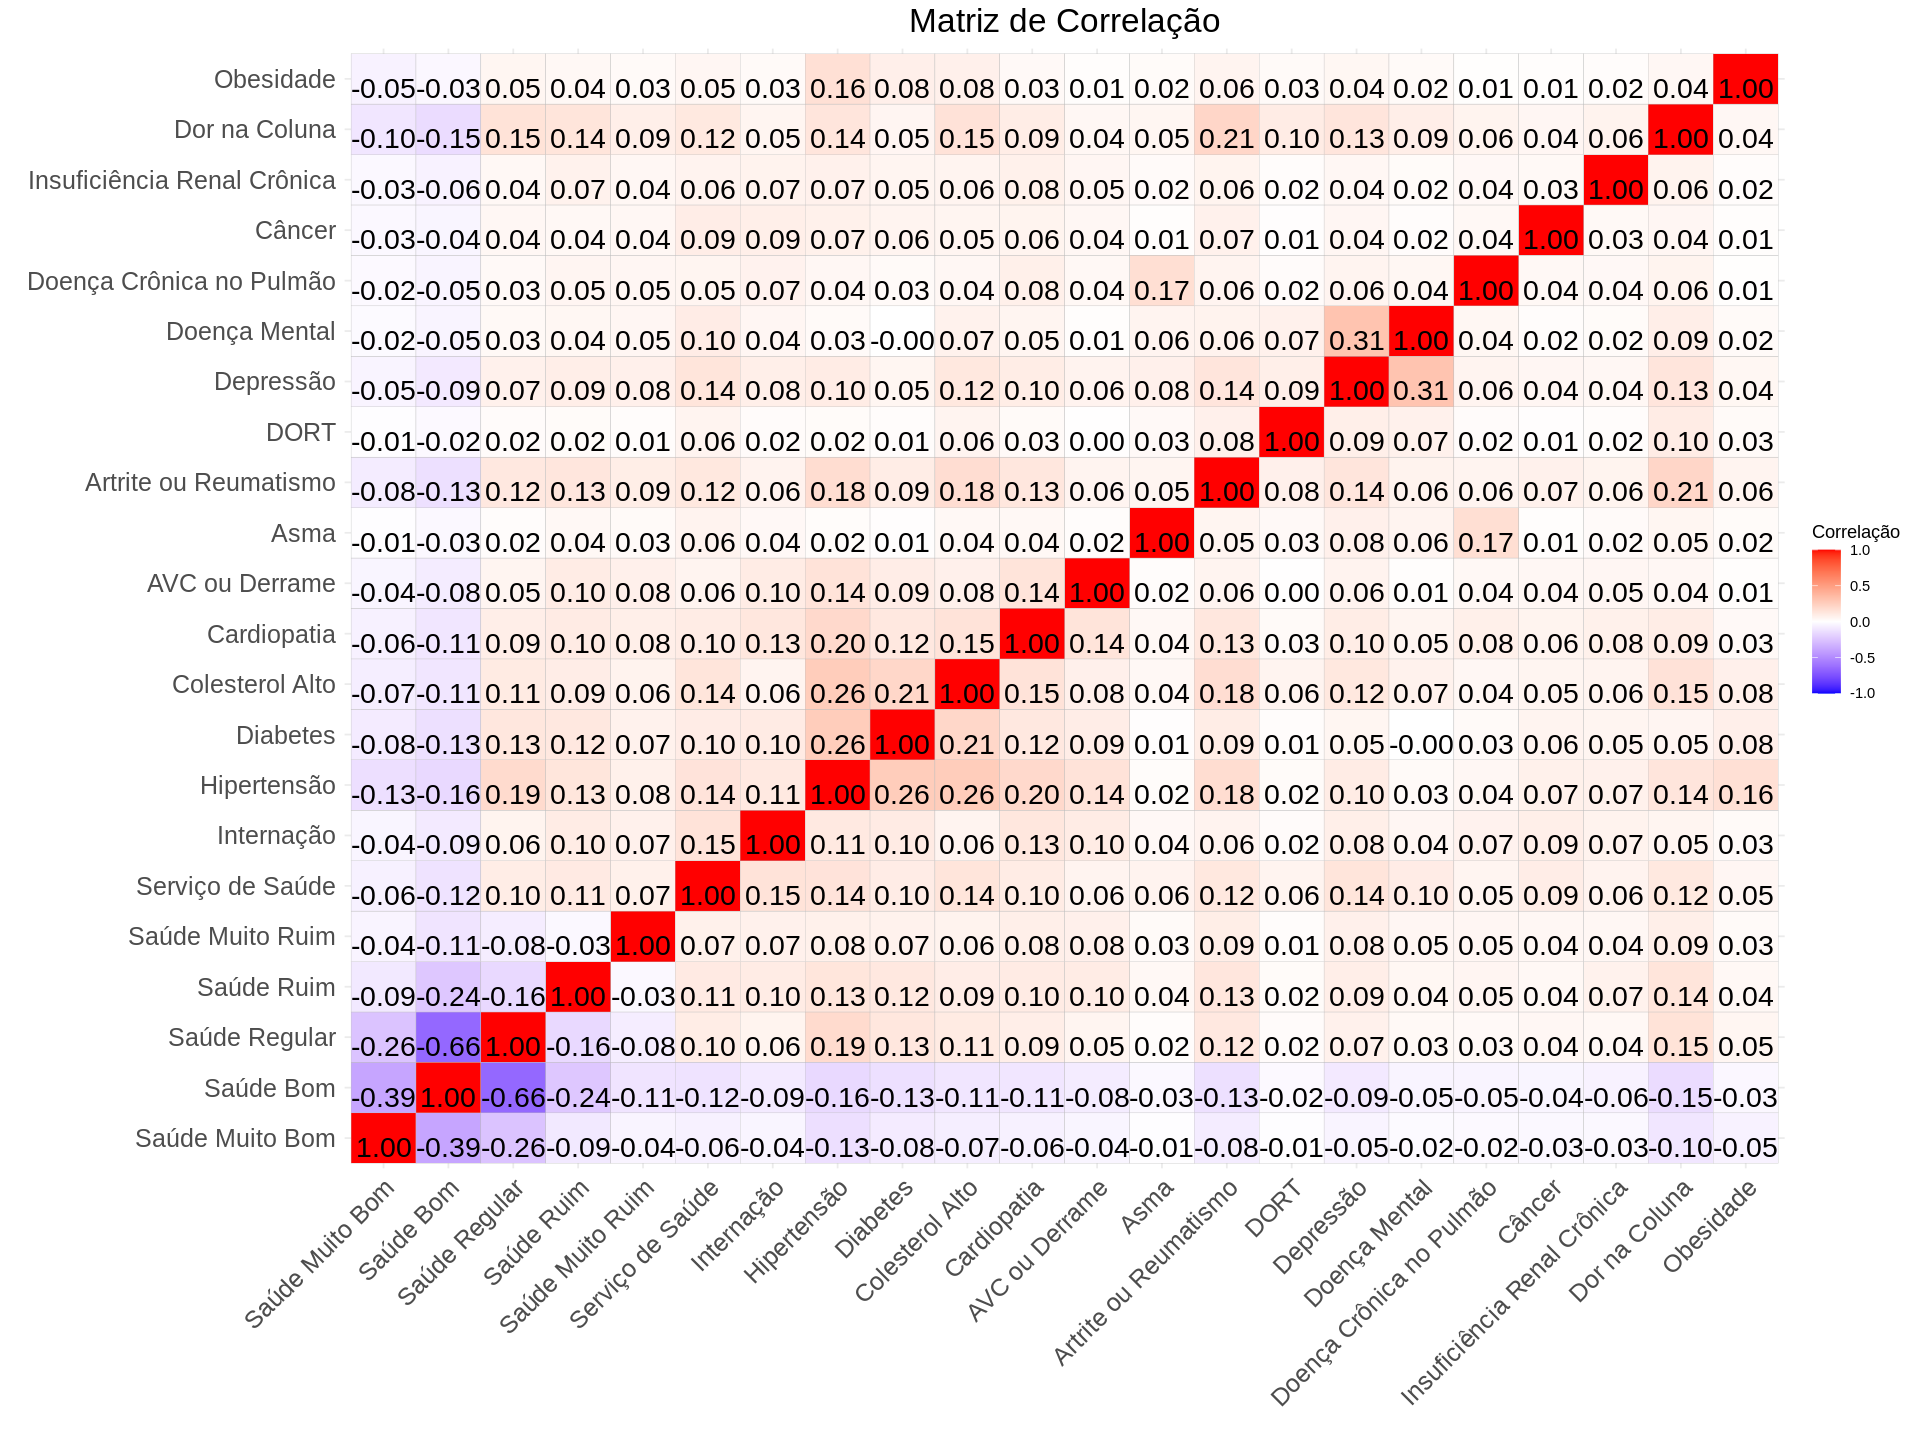

In [17]:
# Copiando variáveis necessárias
dfAnalise_52_bin <- dfPreProcessamento_51_bin

# Calcular a matriz de correlação usando método Pearson
corr_matrix <- cor(dfAnalise_52_bin, use = "pairwise.complete.obs", method = "pearson")

# Transformando a matriz de correlação em um formato longo para plotagem com ggplot2
corr_long <- melt(corr_matrix)

# Configurando o tamanho do dispositivo de plotagem no RStudio
options(repr.plot.width = 16, repr.plot.height = 12)

# Gerando o gráfico
plot <- ggplot(data = corr_long, aes(x = Var1, y = Var2, fill = value)) +
  geom_tile(color = "gray") +  # Ajuste menor: 'Gray' para 'gray'
  geom_text(aes(label = sprintf("%.2f", value)), vjust = 1, size = 6) +
  scale_fill_gradient2(low = "blue", high = "red", mid = "white",
                       midpoint = 0, limit = c(-1, 1), space = "Lab",
                       name="Correlação") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, vjust = 1, size = 15, hjust = 1),
        axis.text.y = element_text(size = 15),
        plot.title = element_text(size = 20, hjust = 0.5)) +
  labs(title = "Matriz de Correlação", x = "", y = "")

# Exibindo o gráfico diretamente
print(plot)

### **5.3 - Grafo de Correlação**

Neste grafo, cada nó representa uma variável e as arestas entre os nós representam as correlações entre as variáveis. As correlações significativas (maiores ou iguais a 0,14 em valor absoluto) são mostradas como arestas no gráfico. Foram dados escolhidos, após análise da matriz de confusão.

Aqui estão algumas observações e deduções que podemos fazer com base no gráfico de correlação:

* As variáveis que estão próximas umas das outras no gráfico têm uma correlação mais forte. Isso indica que essas variáveis tendem a se mover juntas, seja na mesma direção (correlação positiva) ou em direções opostas (correlação negativa).
* As variáveis que estão isoladas no gráfico não têm correlações significativas com outras variáveis. Isso indica que essas variáveis se movem independentemente das outras variáveis no conjunto de dados.
* As variáveis que estão conectadas por várias arestas têm múltiplas correlações significativas com outras variáveis. Isso pode indicar que essas variáveis desempenham um papel importante no conjunto de dados e podem ser importantes para análises futuras.


Warning message:
“`delete.vertices()` was deprecated in igraph 2.0.0.
ℹ Please use `delete_vertices()` instead.”
Warning message:
“`get.edgelist()` was deprecated in igraph 2.0.0.
ℹ Please use `as_edgelist()` instead.”


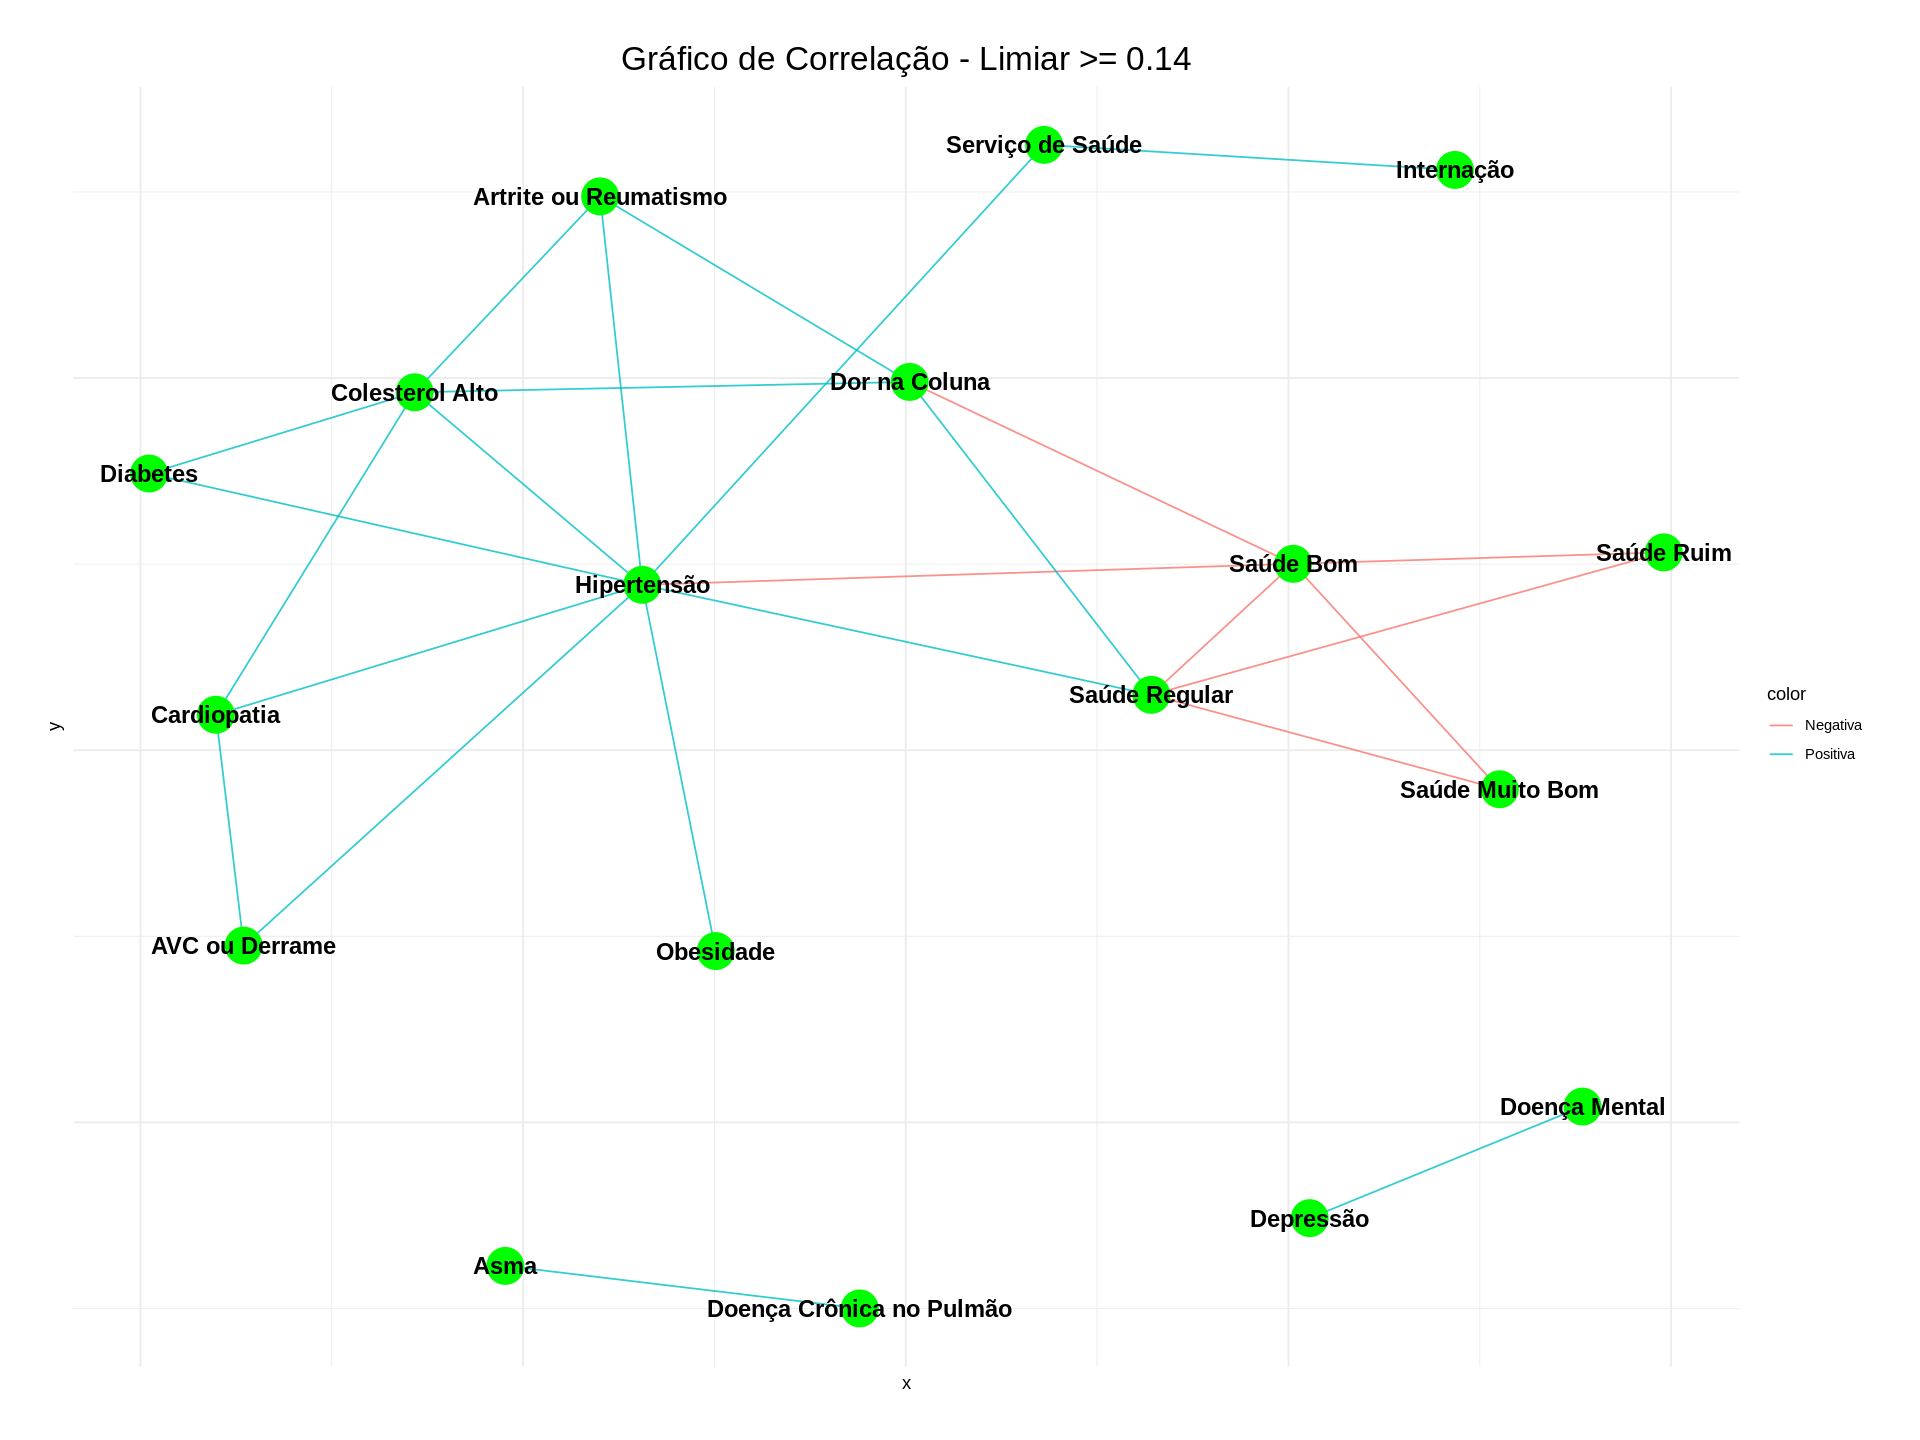

In [18]:
# Copiando variáveis necessárias
dfAnalise_53_bin <- dfPreProcessamento_51_bin

# Calcular a matriz de correlação
corr_matrix <- cor(dfAnalise_53_bin, use = "complete.obs")

# Limiar de correlação
threshold <- 0.14

# Criando uma matriz com os valores absolutos das correlações
abs_corr_matrix <- abs(corr_matrix)

# Filtrar a matriz de correlações absolutas
abs_corr_matrix_filtered <- abs_corr_matrix
abs_corr_matrix_filtered[abs_corr_matrix_filtered < threshold] <- 0

# Criar um grafo a partir da matriz de correlação filtrada
G <- graph_from_adjacency_matrix(abs_corr_matrix_filtered, weighted = TRUE, mode = "undirected", diag = FALSE)

# Remover vértices isolados
G <- delete.vertices(G, degree(G) == 0)

V(G)$name <- colnames(abs_corr_matrix_filtered)[which(colnames(abs_corr_matrix_filtered) %in% V(G)$name)]

# Adicionar atributo de cor para as arestas com base nas correlações originais
E(G)$color <- ifelse(corr_matrix[get.edgelist(G)] > 0, "blue", "red")

# Criar um fator ordenado para a coluna de cores das arestas
E(G)$color <- factor(E(G)$color, levels = c("red", "blue"), labels = c("Negativa", "Positiva"))

# Calcular o comprimento das arestas com base no valor absoluto da correlação
E(G)$length <- abs(corr_matrix[get.edgelist(G)])

# Calcular o layout "Fruchterman Reingold"
layout_fr <- layout_with_fr(G, weights = E(G)$length)

# Normalizar as coordenadas do layout
layout_fr <- layout_fr / max(abs(layout_fr))

# Desenhar o gráfico de correlação
plot <- ggraph(G, layout = layout_fr) +
  geom_edge_link(aes(color = color), edge_alpha = 0.8, show.legend = TRUE) +
  scale_edge_width(range = c(0.5, 3)) +
  geom_node_point(color = "green", size = 10) +
  geom_node_text(aes(label = name), vjust = 0.5, hjust = 0.5, size = 5, fontface = "bold", color = "black") +
  ggtitle(paste("Gráfico de Correlação - Limiar >=", threshold)) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, size = 20),
    legend.position = "right",
    axis.text.x = element_blank(),
    axis.text.y = element_blank(),
    axis.ticks = element_blank(),
    plot.margin = unit(c(1, 1, 1, 1), "cm")
  )

# Exibir o gráfico
print(plot)